# Search: Solving a Maze Using a Goal-based Agent

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Formulate search problems using key components like initial state, actions, and goal state in a deterministic, fully observable environment.
* Implement and compare search algorithms including BFS, DFS, GBFS, A*, and IDS for planning paths through mazes.
* Analyze algorithm performance by measuring path cost, node expansions, depth, and memory usage across various maze types.
* Use visualization tools to represent maze paths and support debugging and analysis.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the notebook file and the completely rendered notebook with all outputs as a HTML file.


## Introduction

In this exercise, we will implement the planning function for a type of goal-based agent called a __planning agent__. The planning function uses a map it is given to plan a path through the maze from the starting location $S$ to the goal location $G$. We will only focus on the planning function, so you do not need to implement an environment, just use the map to search for a path to solve the maze.

Once the plan is made, the agent in a deterministic environment (i.e., the transition function is deterministic with the outcome of each state/action pair fixed and no randomness) can just follow the plan step-by-step and does not need to care about the percepts.
This is also called an **[open-loop system](https://en.wikipedia.org/wiki/Open-loop_controller).**
The execution phase is trivial and can be executed using a model-based reflex agent
that ignores all percepts and just follows the plan. I will show you a short example, but you do not implement it in this exercise.

Given that the agent has a complete and correct map, the environment is **fully observable, discrete, deterministic, and known.**
Remember:

* **Fully observable** means that the agent can see its state and what the available actions are. That means the **percepts contain the complete current state.**
Here, during planning, the agent always sees its x and y coordinates on the map and
also seeks when it has reached the goal state.
* **Discrete** means that we have a **finite set of states.** The maze has a finite set
of squares the agent can be in.
* **Deterministic** means that the **transition function contains no randomness.** An action in a state will always produce the same result. Going south from the start state always will lead to the same square.
* **Know** means that the agent **knows the complete transition function.** The
agent has the map and therefore knows how its position changes when it walks in a direction.

Tree search algorithm implementations that you find online typically come from data structures courses and have a different aim than AI tree search. These algorithms assume that you already have a tree in memory. We are interested in dynamically creating a search tree with the aim of finding a good/the best path from the root note to the goal state. Follow the pseudo code presented in the text book (and replicated in the slides) closely. Ideally, we would like to search only a small part of the maze, i.e., create a search tree with as few nodes as possible.

Several mazes for this exercise are stored as text files. We need to make sure that they are locally available.

In [108]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Your working directory is now Google Drive: My Drive > Colab Notebooks


In [109]:
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

base_url = "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Search/"
download("maze_helper.py", base_url)

mazes = ["small_maze.txt", "medium_maze.txt", "large_maze.txt", "L_maze.txt", "empty_maze.txt", "empty_maze_2.txt", "loops_maze.txt", "open_maze.txt", ]
for maze in mazes:
    download(maze, base_url)

Here is the small example maze:

In [110]:
with open("small_maze.txt", "r") as f:
    maze_str = f.read()
print(maze_str)

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX



**Note:** If you get an error here that the file cannot be found, then you need to download it. See [HOWTO Work on Assignments.](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/working_on_assignments.md)

## Parsing and pretty printing the maze

The maze can also be displayed in color using code in the module [maze_helper.py](maze_helper.py). The code parses the string representing the maze and converts it into a `numpy` 2d array which you can use in your implementation. Position are represented as a 2-tuple of the form `(row, col)`.

In [111]:
import maze_helper as mh

maze = mh.parse_maze(maze_str)

# look at a position in the maze by subsetting the 2d array
print("Position(0,0):", maze[0, 0])

# there is also a helper function called `look(maze, pos)` available
# which uses a 2-tuple for the position.
print("Position(8,1):", mh.look(maze, (8, 1)))

Position(0,0): X
Position(8,1): G


A helper function to visualize the maze is also available.

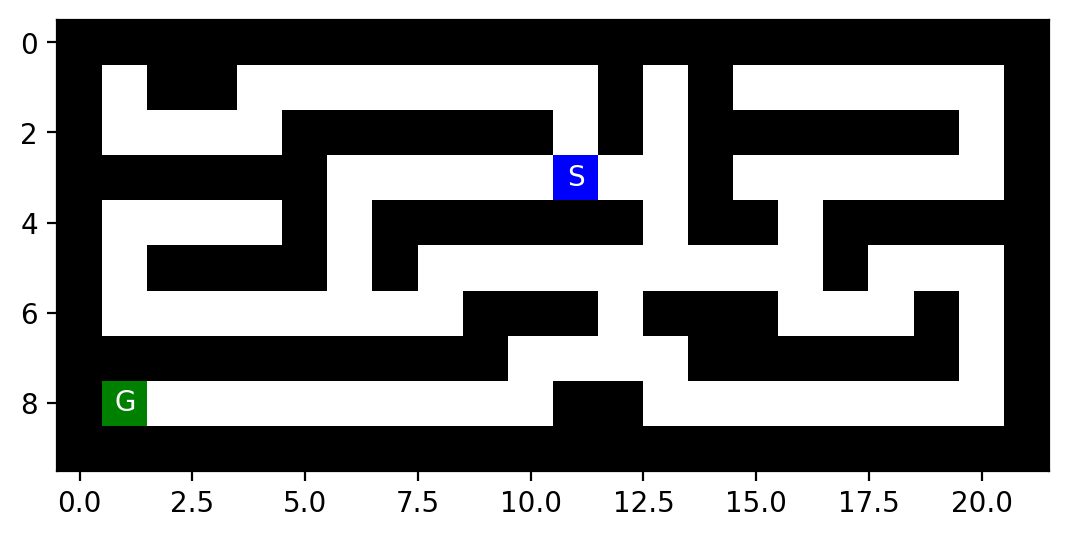

In [112]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
# use higher resolution images in notebooks

mh.show_maze(maze)

Find the `(x,y)` position of the start and the goal using the helper function `find_pos()`

In [113]:
print("Start location:", mh.find_pos(maze, what = "S"))
print("Goal location:", mh.find_pos(maze, what = "G"))

Start location: (np.int64(3), np.int64(11))
Goal location: (np.int64(8), np.int64(1))


Helper function documentation.

In [114]:
help(mh)

Help on module maze_helper:

NAME
    maze_helper

DESCRIPTION
    Code for the Maze Assignment by Michael Hahsler
    Usage:
        import maze_helper as mh
        mh.show_some_mazes()

FUNCTIONS
    animate_maze(result, repeat=False)
        (Experimental) Build an animation from a list of mazes.

        Parameters:
            result: a list with the elements path, reached, actions and maze_anim with a list of maze arrays that contain what you want to visualize.
            repeat: if True, the animation will repeat.

    find_pos(maze, what='S')
        Find start/goal in a maze and returns the first one.
        Caution: there is no error checking!

        Parameters:
            maze: a array with characters produced by parse_maze()
            what: the letter to be found ('S' for start and 'G' for goal)

        Returns:
            a tupple (x, y) for the found position.

    look(maze, pos)
        Look at the label of a square with the position as an array of the form (x

You will need to make a local copy of the module file [maze_helper.py](maze_helper.py) in the same folder where your notebook is.

## An Example for a Planning Agent

I will show you here how to implement a simple agent that uses a random plan. It will not solve the maze, but show you how the mechanics work.

First, we define a generic planning agent that fist plans, and then executes the plan step-by-step.

In [115]:
class Planning_Agent:
    def __init__(self, maze, start, goal, planning_function):
        self.maze = maze
        self.start = start
        self.goal = goal
        self.planning_function = planning_function
        self.plan = None
        self.progress = None

    def act(self):
        # plan if no plan exists
        if self.plan is None:
            print("Planning...")
            self.plan = self.planning_function(self.maze, self.start, self.goal)
            self.progress = 0

        # check if plan is completed
        if self.progress >= len(self.plan):
            raise Exception("Completed Plan. No more planned actions")

        # follow the plan
        action = self.plan[self.progress]
        print(f"Following plan... step {self.progress}: {action}")

        self.progress += 1
        return action

Next, we define the planning function. This function is what you will implement in this assignment.  

In [116]:
import numpy as np

def plan_random(maze, start, goal):
    """Create a random plan with 10 steps"""
    plan = np.random.choice(["N", "E", "S", "W"], size=10, replace=True).tolist()
    return plan

plan_random(maze, (1,1), (8,8))

['W', 'S', 'W', 'E', 'W', 'S', 'E', 'W', 'S', 'W']

This planning function is not great and will not produce a plan that solves the maze. Your planning functions will do better.

Finally, we can create the planning agent, give it the planning function and implement a simple environment that asks it 11 times for an action.

In [117]:
my_agent = Planning_Agent(maze, mh.find_pos(maze, what = "S"), mh.find_pos(maze, what = "G"), plan_random)

def environment(agent_function, steps):
    for _ in range(steps):
        try:
            agent_function()
        except Exception as e:
            print(f"Agent exception: {e}")

environment(my_agent.act, steps=11)

Planning...
Following plan... step 0: S
Following plan... step 1: E
Following plan... step 2: N
Following plan... step 3: S
Following plan... step 4: W
Following plan... step 5: N
Following plan... step 6: N
Following plan... step 7: S
Following plan... step 8: E
Following plan... step 9: W
Agent exception: Completed Plan. No more planned actions


Note: The agent and environment implementation above is just an illustration. You will only implement and experiment with different versions of the planning function.

## Tree structure

To use tree search, you will need to implement a tree data structure in Python.
Here is an implementation of the basic node structure for the search algorithms (see Fig 3.7 on page 73). I have added a method that extracts the path from the root node to the current node. It can be used to get the path when the search is completed.

In [118]:
class Node:
    def __init__(self, pos, parent, action, cost):
        self.pos = tuple(pos)    # the state; positions are (row,col)
        self.parent = parent     # reference to parent node. None means root node.
        self.action = action     # action used in the transition function (root node has None)
        self.cost = cost         # for uniform cost this is the depth. It is also g(n) for A* search
        self.kids = 0            # (thêm) số nút con còn "sống" trong cây; dùng để đo bộ nhớ của DFS

    def __str__(self):
        return f"Node - pos = {self.pos}; action = {self.action}; cost = {self.cost}"

    def get_path_from_root(self):
        """returns nodes on the path from the root to the current node."""
        node = self
        path = [node]

        while not node.parent is None:
            node = node.parent
            path.append(node)

        path.reverse()

        return(path)

If needed, then you can add more fields to the class like the heuristic value $h(n)$ or $f(n)$.

Examples for how to create and use a tree and information on memory management can be found [here](../HOWTOs/trees.ipynb).

# Tasks

The goal is to:

1. Implement the following search algorithms for solving different mazes:

    - Breadth-first search (BFS)
    - Depth-first search (DFS)
    - Greedy best-first search (GBFS)
    - A* search

2. Run each of the above algorithms on the
    - [small maze](small_maze.txt),
    - [medium maze](medium_maze.txt),
    - [large maze](large_maze.txt),
    - [open maze](open_maze.txt),
    - [L maze](L_maze.txt),
    - [loops maze](loops_maze.txt),
    - [empty maze](empty_maze.txt), and
    - [empty maze (rotated)](empty_maze_2.txt).
    
3. For each problem instance and each search algorithm, report the following in a table:

    - The solution and its path cost
    - Total number of nodes expanded
    - Maximum tree depth
    - Maximum size of the frontier

4. Display each solution by marking every maze square (or state) visited and the squares on the final path.

## General [10 Points]

1. Make sure that you use the latest version of this notebook.
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally.
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Defining the search problem and determining the problem size [10 Points]

Define the components of the search problem:

* Initial state
* Actions
* Transition model
* Goal state
* Path cost

Use verbal descriptions, variables and equations as appropriate.

*Note:* You can switch the next block from code to Markdown and use formatting.

### 1.1. Các thành phần của bài toán tìm kiếm

Bài toán giải mê cung (Maze-solving) được mô hình hóa thành một bài toán tìm kiếm, trong đó tác tử cần tìm đường đi từ vị trí bắt đầu đến vị trí đích mà không đi xuyên qua các bức tường.

**1. Trạng thái ban đầu (Initial state)**

Trạng thái ban đầu \(s_0\) là vị trí được đánh dấu `S` trong mê cung. Mỗi trạng thái được biểu diễn bằng một cặp tọa độ \((r,c)\), trong đó \(r\) là chỉ số hàng và \(c\) là chỉ số cột.

**2. Các hành động (Actions)**

Tác tử có thể di chuyển theo bốn hướng: Bắc (North – N), Nam (South – S), Đông (East – E) và Tây (West – W). Một hành động chỉ hợp lệ khi ô đích nằm trong phạm vi mê cung và không phải là tường.

Tập hợp các hành động có thể có được biểu diễn như sau:

$$
A(s)=\{N,S,E,W\}
$$

Tuy nhiên, tại mỗi trạng thái, tác tử chỉ được thực hiện những hành động hợp lệ.

**3. Mô hình chuyển trạng thái (Transition model)**

Mô hình chuyển trạng thái mô tả trạng thái tiếp theo mà tác tử đạt được sau khi thực hiện một hành động hợp lệ. Với trạng thái hiện tại \(s=(r,c)\), các trạng thái kế tiếp tương ứng là:

* Di chuyển lên phía Bắc: \((r-1,c)\).
* Di chuyển xuống phía Nam: \((r+1,c)\).
* Di chuyển sang phía Đông: \((r,c+1)\).
* Di chuyển sang phía Tây: \((r,c-1)\).

Tác tử không được di chuyển ra ngoài ranh giới mê cung hoặc đi vào các ô tường. Do đó, trạng thái tiếp theo chỉ được chấp nhận nếu ô tương ứng là ô có thể di chuyển đến.

**4. Trạng thái đích (Goal state)**

Trạng thái đích \(s_g\) là vị trí được đánh dấu `G` trong mê cung. Quá trình tìm kiếm kết thúc khi tác tử đạt đến trạng thái này.

Hàm kiểm tra trạng thái đích được xác định như sau:

$$
\operatorname{GoalTest}(s)=
\begin{cases}
\text{True}, & \text{nếu }s=s_g\\
\text{False}, & \text{nếu }s\ne s_g
\end{cases}
$$

**5. Chi phí đường đi (Path cost)**

Mỗi bước di chuyển hợp lệ có chi phí bằng 1. Vì vậy, tổng chi phí của một đường đi bằng tổng chi phí của tất cả các bước di chuyển từ trạng thái ban đầu đến trạng thái đích.

Nếu đường đi gồm \(k\) hành động, chi phí đường đi được tính bằng:

$$
g(\text{path})=\sum_{i=1}^{k}1=k
$$

Mục tiêu là tìm một đường đi từ `S` đến `G` với chi phí thấp nhất. Khi mỗi bước di chuyển có cùng chi phí bằng 1, thuật toán BFS và thuật toán A* được cài đặt đúng có thể tìm được đường đi tối ưu. Trong khi đó, DFS và GBFS không đảm bảo luôn tìm được đường đi tối ưu.

### 1.2. Ước lượng quy mô bài toán

Các tham số chính được sử dụng để mô tả quy mô bài toán tìm kiếm bao gồm \(n\), \(d\), \(m\) và \(b\).

| Tham số | Ý nghĩa                                                   | Cách xác định                                                                                                                            |
| ------- | --------------------------------------------------------- | ---------------------------------------------------------------------------------------------------------------------------------------- |
| \(n\)   | Số trạng thái có thể tiếp cận trong không gian trạng thái | Đếm số ô có thể di chuyển đến và có thể tiếp cận từ vị trí bắt đầu; mỗi ô được xem là một trạng thái.                                    |
| \(d\)   | Độ sâu của lời giải tối ưu                                | Xác định số bước di chuyển ít nhất từ `S` đến `G`. Có thể sử dụng BFS để tìm giá trị này khi chi phí mỗi bước bằng 1.                    |
| \(m\)   | Độ sâu tối đa của cây tìm kiếm                            | Xác định mức sâu nhất mà quá trình tìm kiếm có thể đạt tới, phụ thuộc vào thuật toán và cách xử lý các trạng thái lặp.                   |
| \(b\)   | Hệ số phân nhánh tối đa                                   | Đếm số trạng thái kế tiếp hợp lệ của từng trạng thái và lấy giá trị lớn nhất. Với mê cung cho phép di chuyển theo bốn hướng, \(b\leq4\). |

Với một mê cung hữu hạn có \(R\) hàng và \(C\) cột, tổng số ô trong mê cung được tính bằng:

$$
N_{\text{cells}}=R\times C
$$

Tuy nhiên, số trạng thái có thể tiếp cận \(n\) có thể nhỏ hơn tổng số ô vì các ô tường không phải là trạng thái hợp lệ, đồng thời một số ô trống có thể không thể đi đến từ vị trí bắt đầu.

Độ sâu lời giải tối ưu \(d\) là số bước của đường đi ngắn nhất từ điểm bắt đầu đến điểm đích. Độ sâu tối đa của cây tìm kiếm \(m\) phụ thuộc vào cách thuật toán duyệt mê cung và việc có phát hiện, xử lý các trạng thái lặp hoặc chu trình hay không. Hệ số phân nhánh tối đa \(b\) không vượt quá 4 vì tác tử chỉ có thể di chuyển theo bốn hướng.

Các tham số này giúp giải thích sự khác biệt giữa các thuật toán tìm kiếm về số nút được mở rộng, lượng bộ nhớ sử dụng và độ dài đường đi tìm được. Giá trị cụ thể cần được xác định hoặc đo lường cho từng mê cung, thay vì giả định rằng cả tám mê cung đều có cùng quy mô bài toán.

Give some estimates for the problem size:

* $n$: state space size
* $d$: depth of the optimal solution
* $m$: maximum depth of tree
* $b$: maximum branching factor

Describe how you would determine these values for a given maze.

In [119]:
import numpy as np
import pandas as pd
from collections import deque
MAZE_FILES = {
    "small": "small_maze.txt", "medium": "medium_maze.txt", "large": "large_maze.txt",
    "open": "open_maze.txt", "L": "L_maze.txt", "loops": "loops_maze.txt",
    "empty": "empty_maze.txt", "empty_2": "empty_maze_2.txt",
}
mazes_dict = {}
for name, file in MAZE_FILES.items():
    with open(file, "r") as f:
        mazes_dict[name] = mh.parse_maze(f.read())

# Các mê cung đã được nạp vào mazes_dict
# Quy ước: "X" là tường; các ô còn lại là ô có thể đi

DIRECTIONS = [
    (-1, 0),  # Bắc
    (1, 0),   # Nam
    (0, 1),   # Đông
    (0, -1)   # Tây
]

def is_free(maze, r, c):
    """Kiểm tra ô có nằm trong mê cung và không phải tường."""
    return (
        0 <= r < maze.shape[0]
        and 0 <= c < maze.shape[1]
        and maze[r, c] != "X"
    )

def find_position(maze, symbol):
    """Tìm vị trí của S hoặc G."""
    positions = np.argwhere(maze == symbol)
    if len(positions) == 0:
        return None
    return tuple(positions[0])

def analyze_maze(name, maze):
    # Đếm toàn bộ ô không phải tường
    free_cells = [
        (r, c)
        for r in range(maze.shape[0])
        for c in range(maze.shape[1])
        if is_free(maze, r, c)
    ]

    # Tính số hàng xóm hợp lệ của mỗi ô
    degrees = []
    for r, c in free_cells:
        degree = sum(
            is_free(maze, r + dr, c + dc)
            for dr, dc in DIRECTIONS
        )
        degrees.append(degree)

    # Tìm số trạng thái thực sự tiếp cận được từ S bằng BFS
    start = find_position(maze, "S")
    reachable = set()

    if start is not None:
        queue = deque([start])
        reachable.add(start)

        while queue:
            r, c = queue.popleft()

            for dr, dc in DIRECTIONS:
                nr, nc = r + dr, c + dc
                nxt = (nr, nc)

                if is_free(maze, nr, nc) and nxt not in reachable:
                    reachable.add(nxt)
                    queue.append(nxt)

    return {
        "Mê cung": name,
        "Kích thước": f"{maze.shape[0]}x{maze.shape[1]}",
        "Tổng ô không phải tường": len(free_cells),
        "n (trạng thái tiếp cận được)": len(reachable),
        "b tối đa": max(degrees) if degrees else 0,
        "b trung bình": round(float(np.mean(degrees)), 2)
            if degrees else 0
    }

rows = [
    analyze_maze(name, maze)
    for name, maze in mazes_dict.items()
]

df_task1 = pd.DataFrame(rows)
display(df_task1)

,Mê cung,Kích thước,Tổng ô không phải tường,n (trạng thái tiếp cận được),b tối đa,b trung bình
0,small,10x22,94,94,3,2.02
1,medium,18x36,274,274,3,2.04
2,large,37x37,647,647,4,2.00
3,open,23x37,684,684,4,3.69
4,L,15x15,157,157,4,3.50
5,loops,12x12,72,72,4,2.58
6,empty,12x12,100,100,4,3.60
7,empty_2,12x12,100,100,4,3.60


### Cách xác định các đại lượng của bài toán

* **\(n\) – Số trạng thái:** Đếm số ô có thể đi qua trong mê cung. Tuy nhiên, số trạng thái tiếp cận được từ trạng thái bắt đầu \(S\) có thể nhỏ hơn tổng số ô đi được nếu có những vùng bị cô lập. Khi sử dụng tập `reached`, mỗi trạng thái được ghi nhận để hạn chế việc mở rộng lặp lại.

* **\(b\) – Hệ số nhánh:** Là số hành động hợp lệ có thể thực hiện từ một trạng thái. Trong mê cung sử dụng bốn hướng Bắc, Nam, Đông và Tây, ta có \(b \leq 4\). Các hành động hợp lệ phụ thuộc vào vị trí hiện tại và các ô tường xung quanh.

* **\(d\) – Độ sâu lời giải tối ưu:** Là số bước đi của đường đi ngắn nhất từ \(S\) đến đích \(G\). Có thể sử dụng thuật toán BFS để xác định \(d\), vì mỗi bước di chuyển có chi phí bằng 1. Khoảng cách Manhattan \(|r_s-r_g|+|c_s-c_g|\) có thể dùng làm cận dưới cho số bước cần thiết.

* **\(m\) – Độ sâu tối đa của cây tìm kiếm:** Là độ sâu lớn nhất được xét trong quá trình tìm kiếm. Giá trị này phụ thuộc vào thuật toán, cách quản lý trạng thái đã thăm và cách xử lý chu trình. Trong bài thực nghiệm, có thể ghi nhận giá trị độ sâu tối đa thực tế từ quá trình chạy thuật toán.

Các đại lượng được xác định nhằm mô tả kích thước không gian trạng thái, số hành động có thể thực hiện và độ sâu của quá trình tìm kiếm. Kết quả thực nghiệm của từng mê cung sẽ được trình bày và so sánh ở Task 4.

## Task 2: Uninformed search: Breadth-first and depth-first [40 Points]

Implement these search strategies. Follow the pseudocode in the textbook/slides. You can use the tree structure shown above to extract the final path from your solution.

Read the following **important notes** carefully:
* You can find maze solving implementations online that use the map to store information. While this is an effective idea for this two-dimensional navigation problem, it typically cannot be used for other search problems. Therefore, follow the textbook and **do not store information in the map.** Only store information in the tree created during search, and use the `reached` and `frontier` data structures where appropriate.
* DSF behavior can be implemented using the BFS tree search algorithm and simply changing the order in which the frontier is expanded (this is equivalent to best-first search with path length as the criterion to expand the next node). However, this would be a big mistake since it combines the bad space complexity of BFS with the bad time complexity of DFS! **To take advantage of the significantly smaller memory footprint of DFS, you need to implement DFS in a different way without a `reached` data structure (often also called `visited` or `explored`) and by releasing the memory for nodes that are not needed anymore.**
* Since the proper implementation of DFS does not use a `reached` data structure, redundant path checking abilities are limited to cycle checking.
You need to implement **cycle checking since DSF is incomplete (produces an infinite loop) if cycles cannot be prevented.** You will see in your experiments that cycle checking in open spaces is challenging.

In [120]:
import time, heapq
from collections import deque
import numpy as np

# Bốn hành động; thứ tự này quyết định thứ tự sinh nút con (quan trọng với DFS).
ACTIONS = {"N": (-1, 0), "E": (0, 1), "S": (1, 0), "W": (0, -1)}

# Chốt an toàn: dừng khi số nút mở rộng vượt ngưỡng (để thuật toán không treo vô hạn). Kết quả ghi là "N/A*".
MAX_EXPANSIONS = 1_000_000


def find_goals(maze):
    """Trả về tập mọi ô đích 'G' (hỗ trợ nhiều đích)."""
    rr, cc = np.where(maze == "G")
    return frozenset(zip(rr.tolist(), cc.tolist()))


def get_problem(maze):
    """Đọc bài toán từ bản đồ: (trạng thái đầu, tập trạng thái đích)."""
    start = tuple(int(x) for x in mh.find_pos(maze, "S"))
    return start, find_goals(maze)


def expand(maze, node):
    """Hàm chuyển trạng thái: sinh các nút con hợp lệ (ô không phải tường). Chi phí mỗi bước = 1."""
    children = []
    for action, (dr, dc) in ACTIONS.items():
        pos = (node.pos[0] + dr, node.pos[1] + dc)
        if mh.look(maze, pos) != "X":
            children.append(Node(pos, node, action, node.cost + 1))
    return children


def new_stats():
    # exp_pos / frontier_pos CHỈ dùng để vẽ hình sau khi tìm xong, thuật toán không dùng chúng để ra quyết định
    return dict(expanded=0, max_depth=0, max_frontier=0, max_memory=0, exp_pos=set())


def make_result(status, node, st, t0, frontier=()):
    """Gói kết quả. status: solved | failure | cutoff | limit (vượt MAX_EXPANSIONS)."""
    path = node.get_path_from_root() if node is not None else None
    return dict(status=status, path=path,
                cost=node.cost if node is not None else None,
                actions=[n.action for n in path[1:]] if path else None,
                expanded=st["expanded"], max_depth=st["max_depth"],
                max_frontier=st["max_frontier"], max_memory=st["max_memory"],
                time=time.perf_counter() - t0,
                expanded_pos=st["exp_pos"], frontier_pos=[n.pos for n in frontier])


# ----------------------------------------------------------------------------
# BFS  (graph search: frontier = hàng đợi FIFO, reached = dict trạng thái -> nút; kiểm tra đích khi SINH nút)
# ----------------------------------------------------------------------------
def bfs(maze, start, goals):
    t0 = time.perf_counter(); st = new_stats()
    root = Node(start, None, None, 0)
    if root.pos in goals:
        return make_result("solved", root, st, t0)
    frontier = deque([root])
    reached = {root.pos: root}
    st["max_frontier"] = st["max_memory"] = 1
    while frontier:
        node = frontier.popleft()
        st["expanded"] += 1; st["exp_pos"].add(node.pos)
        for child in expand(maze, node):
            if child.pos in goals:                       # early goal test
                st["max_depth"] = max(st["max_depth"], child.cost)
                return make_result("solved", child, st, t0, frontier)
            if child.pos not in reached:                 # redundant-path checking bằng reached
                reached[child.pos] = child
                frontier.append(child)
                st["max_depth"] = max(st["max_depth"], child.cost)
        st["max_frontier"] = max(st["max_frontier"], len(frontier))
        st["max_memory"] = max(st["max_memory"], len(reached))   # BFS giữ MỌI nút đã sinh trong reached
    return make_result("failure", None, st, t0)


# ----------------------------------------------------------------------------
# DFS  (KHÔNG có reached; chỉ có cycle checking trên đường đi từ gốc tới nút hiện tại)
# ----------------------------------------------------------------------------
def is_cycle(node):
    """Cycle check: trạng thái của node có trùng với một tổ tiên của nó không? Chi phí O(độ sâu)."""
    p = node.parent
    while p is not None:
        if p.pos == node.pos:
            return True
        p = p.parent
    return False


def release(node):
    """Giải phóng bộ nhớ: nút lá không còn con nào sống thì bỏ nó, rồi bỏ tiếp các tổ tiên đã hết con.
    Trả về số nút vừa được giải phóng. (Python tự thu gom rác vì không còn tham chiếu tới nút đó.)"""
    freed = 0
    while node is not None and node.kids == 0:
        freed += 1
        parent = node.parent
        if parent is not None:
            parent.kids -= 1
        node = parent
    return freed


def dfs_core(maze, start, goals, limit=None, stats=None, t0=None):
    """DFS (có thể giới hạn độ sâu `limit` -> dùng lại cho IDS). Trả về (result, cutoff)."""
    t0 = t0 or time.perf_counter()
    st = stats or new_stats()
    root = Node(start, None, None, 0)
    frontier = [root]                      # ngăn xếp LIFO
    live = 1                               # số nút đang còn trong bộ nhớ (frontier + tổ tiên của chúng)
    cutoff = False
    st["max_frontier"] = max(st["max_frontier"], 1); st["max_memory"] = max(st["max_memory"], 1)
    while frontier:
        node = frontier.pop()
        if node.pos in goals:                                  # kiểm tra đích khi LẤY nút ra
            return make_result("solved", node, st, t0, frontier), cutoff
        if limit is not None and node.cost >= limit:           # chạm giới hạn độ sâu (dùng cho IDS)
            cutoff = True
            live -= release(node)
            continue
        if st["expanded"] >= MAX_EXPANSIONS:
            return make_result("limit", None, st, t0, frontier), cutoff
        st["expanded"] += 1; st["exp_pos"].add(node.pos)
        added = 0
        for child in expand(maze, node):
            if is_cycle(child):                                # cycle checking
                continue
            node.kids += 1
            frontier.append(child)
            added += 1
            st["max_depth"] = max(st["max_depth"], child.cost)
        live += added
        if added == 0:                                         # ngõ cụt: bỏ nhánh này khỏi bộ nhớ
            live -= release(node)
        st["max_frontier"] = max(st["max_frontier"], len(frontier))
        st["max_memory"] = max(st["max_memory"], live)
    return make_result("cutoff" if cutoff else "failure", None, st, t0), cutoff


def dfs(maze, start, goals):
    return dfs_core(maze, start, goals)[0]

In [121]:
def validate(maze, res):
    """Kiểm tra đường đi do BFS/DFS trả về."""

    # Nếu không tìm được lời giải thì không thể kiểm tra đường đi
    if res["status"] != "solved":
        return False

    start, goals = get_problem(maze)
    pos = start

    for action in res["actions"]:
        dr, dc = ACTIONS[action]
        pos = (pos[0] + dr, pos[1] + dc)

        assert mh.look(maze, pos) != "X", \
            "Đường đi đâm vào tường"

    assert pos in goals, "Đường đi không tới đích"
    assert len(res["actions"]) == res["cost"]

    return True

In [122]:
# Chạy thử BFS và DFS trên small maze
m = mazes_dict["small"]
start, goals = get_problem(m)

for name, algo in [("BFS", bfs), ("DFS", dfs)]:
    r = algo(m, start, goals)

    # Kiểm tra đường đi
    valid = validate(m, r)

    print(f"\n===== {name} =====")
    print("Trạng thái:", r["status"])
    print("Đường đi hợp lệ:", valid)
    print("Chi phí đường đi:", r["cost"])
    print("Số node mở rộng:", r["expanded"])
    print("Độ sâu tối đa:", r["max_depth"])
    print("Frontier tối đa:", r["max_frontier"])
    print("Bộ nhớ tối đa (số node):", r["max_memory"])
    print("Thời gian (giây):", round(r["time"], 6))

    if r["status"] == "solved":
        print("Chuỗi hành động:", "".join(r["actions"]))


===== BFS =====
Trạng thái: solved
Đường đi hợp lệ: True
Chi phí đường đi: 19
Số node mở rộng: 90
Độ sâu tối đa: 19
Frontier tối đa: 9
Bộ nhớ tối đa (số node): 92
Thời gian (giây): 0.000545
Chuỗi hành động: EESSWSSWWSWWWWWWWWW

===== DFS =====
Trạng thái: solved
Đường đi hợp lệ: True
Chi phí đường đi: 29
Số node mở rộng: 39
Độ sâu tối đa: 29
Frontier tối đa: 5
Bộ nhớ tối đa (số node): 34
Thời gian (giây): 0.001529
Chuỗi hành động: WWWWWSSSEENEEEESSWWSWWWWWWWWW


How does BFS and DFS (without a reached data structure) deal with loops (cycles)?

### BFS và DFS xử lý chu trình như thế nào?

**BFS:** BFS sử dụng cấu trúc dữ liệu `reached` (ánh xạ trạng thái → nút) để ghi nhớ các trạng thái đã được phát hiện. Nếu một trạng thái đã có trong `reached`, BFS sẽ không thêm trạng thái đó vào `frontier` lần nữa. Nhờ vậy, các đường đi dư thừa và chu trình được loại bỏ, tránh việc mở rộng lặp lại cùng một trạng thái. Do đó, BFS không bị lặp vô hạn khi tìm kiếm trong mê cung có chu trình.

**DFS không sử dụng `reached`:** DFS sử dụng kỹ thuật *cycle checking* để kiểm tra xem trạng thái của nút con có trùng với trạng thái của một nút tổ tiên trên đường đi hiện tại hay không. Nếu trùng, nút con sẽ bị bỏ qua. Cách này ngăn DFS đi vòng lặp trên cùng một đường đi, nhưng không ghi nhớ các trạng thái đã duyệt ở những nhánh khác. Vì vậy, cùng một trạng thái vẫn có thể được khám phá nhiều lần thông qua các đường đi khác nhau, làm tăng đáng kể thời gian tìm kiếm.

Trong thực nghiệm, DFS có thể hoạt động hiệu quả trên các mê cung hẹp, nhưng gặp khó khăn ở những vùng trống do có nhiều đường đi khác nhau. Trên mê cung `open`, DFS có thể vượt ngưỡng 1.000.000 lần mở rộng mà vẫn chưa tìm được đích. Kết quả còn phụ thuộc vào thứ tự duyệt các hành động. Trong thử nghiệm với 24 thứ tự hành động và giới hạn 20.000 lần mở rộng, chỉ có 3/24 trường hợp tìm được lời giải cho mê cung `open`.

In [123]:
# Thử nghiệm phụ: DFS trên open maze với 24 thứ tự hành động khác nhau (ngưỡng nhỏ để chạy nhanh)
import itertools
D = {"N": (-1, 0), "E": (0, 1), "S": (1, 0), "W": (0, -1)}
saved_actions, saved_cap = dict(ACTIONS), MAX_EXPANSIONS
MAX_EXPANSIONS = 20_000
solved = []
try:
    m = mazes_dict["open"]; start, goals = get_problem(m)
    for order in itertools.permutations("NESW"):
        ACTIONS.clear(); ACTIONS.update({a: D[a] for a in order})
        r = dfs(m, start, goals)
        if r["status"] == "solved":
            solved.append((" ".join(order), r["cost"], r["expanded"]))
finally:                                   # luôn khôi phục cấu hình gốc
    ACTIONS.clear(); ACTIONS.update(saved_actions); MAX_EXPANSIONS = saved_cap
print(f"DFS giải được open maze trong 20.000 lần mở rộng với {len(solved)}/24 thứ tự hành động:")
for o in solved: print("  thứ tự", o[0], "-> cost", o[1], ", expanded", o[2])

DFS giải được open maze trong 20.000 lần mở rộng với 3/24 thứ tự hành động:
  thứ tự N E W S -> cost 146 , expanded 146
  thứ tự N W S E -> cost 206 , expanded 206
  thứ tự E N W S -> cost 68 , expanded 68


Are your implementations complete and optimal? Explain why. What is the time and space complexity of each of **your** implementations? Especially discuss the difference in space complexity between BFS and DFS.

### 1. Tính đầy đủ và tính tối ưu của các thuật toán

**BFS (Breadth-First Search):**

BFS có tính đầy đủ vì thuật toán lần lượt duyệt các trạng thái có thể tiếp cận và sử dụng cấu trúc `reached` để tránh thêm một trạng thái đã được phát hiện vào hàng đợi nhiều lần. Trong mê cung hữu hạn, nếu tồn tại đường đi đến đích thì BFS có thể tìm thấy lời giải.

BFS có tính tối ưu trong bài toán này vì mỗi bước di chuyển có chi phí bằng 1. Thuật toán tìm kiếm theo từng mức độ sâu nên đường đi tìm được đến đích có chi phí nhỏ nhất.

**DFS (Depth-First Search):**

DFS sử dụng ngăn xếp để ưu tiên mở rộng các nút sâu hơn. Thuật toán kiểm tra chu trình bằng cách so sánh trạng thái con với các trạng thái trên đường đi hiện tại, giúp tránh lặp vô hạn trên cùng một nhánh. Tuy nhiên, do không sử dụng `reached` toàn cục, một trạng thái vẫn có thể được khám phá lại thông qua các đường đi khác nhau.

DFS không bảo đảm tính tối ưu vì đường đi đầu tiên tìm được có thể dài hơn đường đi ngắn nhất. Ngoài ra, implementation có giới hạn số nút mở rộng, vì vậy thuật toán có thể dừng trước khi tìm thấy lời giải nếu đạt giới hạn này.

### 2. Độ phức tạp thời gian và bộ nhớ

Gọi:

* \(b\) là hệ số phân nhánh trung bình.
* \(d\) là độ sâu của lời giải nông nhất.
* \(m\) là độ sâu tối đa của cây tìm kiếm.
* \(V\) là số trạng thái có thể tiếp cận.
* \(E\) là số cạnh nối giữa các trạng thái.

| Thuật toán                              | Độ phức tạp thời gian                           | Độ phức tạp bộ nhớ                                                     |
| --------------------------------------- | ----------------------------------------------- | ---------------------------------------------------------------------- |
| BFS có `reached`                        | \(O(V+E)\)                                      | \(O(V)\)                                                               |
| DFS có kiểm tra chu trình trên đường đi | \(O(b^m)\) trong mô hình cây tìm kiếm tổng quát | Có thể đạt \(O(bm)\) nếu tính cả frontier và cây tìm kiếm được giữ lại |

Đối với mê cung dạng lưới, mỗi trạng thái có tối đa 4 hướng di chuyển nên \(E=O(V)\). Vì vậy, độ phức tạp thời gian của BFS có thể viết gọn thành \(O(V)\).

### 3. So sánh bộ nhớ giữa BFS và DFS

BFS thường sử dụng nhiều bộ nhớ hơn DFS vì phải lưu các trạng thái đã phát hiện trong `reached` và các nút đang chờ trong frontier. Khi mê cung rộng, số trạng thái cần lưu có thể tăng đáng kể.

Ngược lại, DFS chủ yếu đi sâu theo một nhánh và kiểm tra chu trình bằng cách xét các nút tổ tiên. Implementation còn sử dụng hàm `release()` để giải phóng các nút không còn cần thiết, giúp giảm lượng bộ nhớ được giữ lại.

Tuy nhiên, DFS không phải lúc nào cũng chỉ dùng \(O(m)\) bộ nhớ, vì nó còn phải lưu các nhánh đang chờ và một phần cây tìm kiếm. Việc không dùng `reached` toàn cục giúp giảm chi phí lưu trữ trạng thái nhưng có thể khiến DFS khám phá cùng một trạng thái qua nhiều đường đi khác nhau, làm tăng thời gian chạy.

**Kết luận:** BFS phù hợp khi cần tìm đường đi ngắn nhất và tránh khám phá lặp trạng thái, nhưng thường tốn bộ nhớ hơn. DFS có thể tiết kiệm bộ nhớ trong nhiều trường hợp, nhưng không bảo đảm tìm được đường đi ngắn nhất và có thể mất nhiều thời gian khi gặp các mê cung có nhiều chu trình hoặc nhánh sâu.

**Quy mô bài toán của từng mê cung** (tính bằng BFS ở trên): $n$ là số ô đi được, $b$ là hệ số nhánh tối đa, $d$ là độ sâu lời giải tối ưu (BFS tìm đích nông nhất nên cho đúng $d$), $m$ là độ sâu tối đa của cây BFS.

In [124]:
rows = []
for name, m in mazes_dict.items():
    s, gs = get_problem(m)
    r = bfs(m, s, gs)
    t = analyze_maze(name, m)
    rows.append({"maze": name, "n (số ô đi được)": t["n (trạng thái tiếp cận được)"],
                 "b (nhánh tối đa)": t["b tối đa"],
                 "d (độ sâu tối ưu)": r["cost"], "m (độ sâu tối đa của cây BFS)": r["max_depth"]})
pd.DataFrame(rows).set_index("maze")

,n (số ô đi được),b (nhánh tối đa),d (độ sâu tối ưu),m (độ sâu tối đa của cây BFS)
maze,,,,
small,94,3,19,19
medium,274,3,68,68
large,647,4,210,210
open,684,4,54,54
L,157,4,16,16
loops,72,4,23,23
empty,100,4,14,14
empty_2,100,4,14,14


## Task 3: Informed search: Implement greedy best-first search and A* search  [20 Points]

You can use the map to estimate the distance from your current position to the goal using the Manhattan distance (see https://en.wikipedia.org/wiki/Taxicab_geometry) as a heuristic function. Both algorithms are based on Best-First search which requires only a small change from the BFS algorithm you have already implemented (see textbook/slides).

In [125]:
def manhattan(pos, goals):
    """Heuristic h(n): khoảng cách Manhattan tới đích GẦN NHẤT (với 1 đích thì chính là Manhattan thông thường)."""
    return min(abs(pos[0] - g[0]) + abs(pos[1] - g[1]) for g in goals)


def euclidean(pos, goals):
    """Heuristic khác để so sánh: khoảng cách đường chim bay tới đích gần nhất."""
    return min(((pos[0] - g[0]) ** 2 + (pos[1] - g[1]) ** 2) ** 0.5 for g in goals)


HEURISTICS = {"manhattan": manhattan, "euclidean": euclidean}


def best_first(maze, start, goals, kind="astar", weight=1.0, heuristic="manhattan"):
    """Best-first search
    kind='gbfs'  : f(n) = h(n)
    kind='astar' : f(n) = g(n) + weight * h(n)   (weight = 1 là A* thường, weight > 1 là Weighted A*)"""
    t0 = time.perf_counter(); st = new_stats()
    h = HEURISTICS[heuristic]
    if kind == "gbfs":
        f = lambda n: h(n.pos, goals)
    else:
        f = lambda n: n.cost + weight * h(n.pos, goals)
    root = Node(start, None, None, 0)
    tie = 0                                    # số thứ tự để phá hòa khi f bằng nhau (heapq không so sánh được Node)
    frontier = [(f(root), tie, root)]          # hàng đợi ưu tiên (min-heap)
    reached = {root.pos: root}
    stale = 0                                  # số phần tử lỗi thời trong heap (đã có đường rẻ hơn tới cùng ô)
    st["max_frontier"] = st["max_memory"] = 1
    while frontier:
        _, _, node = heapq.heappop(frontier)
        if reached[node.pos] is not node:      # bản cũ đã bị thay bằng đường rẻ hơn -> bỏ
            stale -= 1
            continue
        if node.pos in goals:                  # late goal test (cần cho tính tối ưu của A*)
            return make_result("solved", node, st, t0, [e[2] for e in frontier])
        st["expanded"] += 1; st["exp_pos"].add(node.pos)
        for child in expand(maze, node):
            old = reached.get(child.pos)
            # thêm nút con nếu ô này mới, hoặc vừa tìm được đường rẻ hơn tới nó
            if old is None or child.cost < old.cost:
                if old is not None:
                    stale += 1
                reached[child.pos] = child
                tie += 1
                heapq.heappush(frontier, (f(child), tie, child))
                st["max_depth"] = max(st["max_depth"], child.cost)
        st["max_frontier"] = max(st["max_frontier"], len(frontier) - stale)
        st["max_memory"] = max(st["max_memory"], len(reached))
    return make_result("failure", None, st, t0)


def gbfs(maze, start, goals, heuristic="manhattan"):
    return best_first(maze, start, goals, "gbfs", heuristic=heuristic)


def astar(maze, start, goals, weight=1.0, heuristic="manhattan"):
    return best_first(maze, start, goals, "astar", weight=weight, heuristic=heuristic)

In [126]:
maze = mazes_dict["small"]
start, goals = get_problem(maze)

for name, algo in [("GBFS", gbfs), ("A*", astar)]:
    result = algo(maze, start, goals)

    print(f"\n===== {name} =====")
    print("Trạng thái:", result["status"])
    print("Chi phí đường đi:", result["cost"])
    print("Số node mở rộng:", result["expanded"])
    print("Độ sâu tối đa:", result["max_depth"])
    print("Frontier tối đa:", result["max_frontier"])
    print("Bộ nhớ tối đa:", result["max_memory"])
    print("Thời gian:", round(result["time"], 6), "giây")

    if result["status"] == "solved":
        print("Đường đi:", "".join(result["actions"]))
        print("Đường đi hợp lệ:", validate(maze, result))


===== GBFS =====
Trạng thái: solved
Chi phí đường đi: 29
Số node mở rộng: 39
Độ sâu tối đa: 29
Frontier tối đa: 5
Bộ nhớ tối đa: 44
Thời gian: 0.000341 giây
Đường đi: WWWWWSSSEENEEEESSWWSWWWWWWWWW
Đường đi hợp lệ: True

===== A* =====
Trạng thái: solved
Chi phí đường đi: 19
Số node mở rộng: 53
Độ sâu tối đa: 19
Frontier tối đa: 8
Bộ nhớ tối đa: 59
Thời gian: 0.000392 giây
Đường đi: EESSWSSWWSWWWWWWWWW
Đường đi hợp lệ: True


Are your implementations complete and optimal? What is the time and space complexity?

### Tính đầy đủ, tính tối ưu và độ phức tạp của GBFS và A*

Heuristic dùng ở đây là khoảng cách Manhattan tới đích gần nhất: $h(n) = |r - r_g| + |c - c_g|$. Gọi $b$ là hệ số nhánh, $d$ là độ sâu của lời giải tối ưu, $m$ là độ sâu tối đa của cây.

**GBFS** dùng $f(n) = h(n)$.

* *Đầy đủ:* có, vì mê cung hữu hạn và có bảng `reached` nên không bị lặp vô hạn.
* *Tối ưu:* **không**. GBFS chỉ nhìn $h(n)$ mà bỏ qua $g(n)$, nên cứ lao thẳng về phía đích và trả về đường đầu tiên tìm được, dù nó dài (xem small, medium, open, L ở bảng kết quả).
* *Độ phức tạp:* trong trường hợp xấu nhất thời gian và bộ nhớ là $O(b^m)$, nhưng thực tế heuristic tốt thì chạy rất nhanh.

**A\*** dùng $f(n) = g(n) + h(n)$.

* *Đầy đủ:* có (mê cung hữu hạn, mọi bước đi tốn 1).
* *Tối ưu:* **có**. Manhattan không bao giờ lớn hơn khoảng cách thật khi chỉ đi được 4 hướng (admissible) và còn nhất quán (consistent). Hai chi tiết trong code quan trọng cho tính tối ưu: kiểm tra đích khi **lấy nút ra khỏi hàng đợi** (không phải lúc sinh nút), và nếu tìm được đường rẻ hơn tới một ô đã `reached` thì thêm lại ô đó.
* *Độ phức tạp:* trường hợp xấu nhất vẫn là $O(b^d)$ về thời gian và bộ nhớ, nhưng heuristic cắt bớt rất nhiều nút nên A\* mở rộng ít nút hơn BFS ở hầu hết các mê cung.

Cả hai đều phải giữ `reached` và hàng đợi ưu tiên trong bộ nhớ, nên bộ nhớ cùng bậc với BFS (khác với DFS/IDS).

**Dùng thuật toán tìm kiếm trong planning agent.** Đề bài muốn có một planning agent hoàn chỉnh, nên ở đây hàm lập kế hoạch của `Planning_Agent` là một thuật toán tìm kiếm thật (A\*) thay cho `plan_random`. Hàm bọc trả về danh sách hành động `N/E/S/W`, agent đi theo kế hoạch từng bước, rồi mình mô phỏng lại các hành động để kiểm tra agent có thực sự dừng đúng ô đích không.

In [127]:
def make_planner(search):
    """Biến một thuật toán tìm kiếm thành planning function (maze, start, goal) -> danh sách hành động."""
    def planner(maze, start, goal):
        s, gs = get_problem(maze)          # các hàm tìm kiếm tự đọc S và G từ bản đồ
        return search(maze, s, gs)["actions"]
    return planner


def follow_plan(start, plan):
    """Mô phỏng thực hiện kế hoạch bằng mô hình chuyển trạng thái, trả về vị trí cuối."""
    pos = tuple(int(x) for x in start)
    for a in plan:
        dr, dc = ACTIONS[a]
        pos = (pos[0] + dr, pos[1] + dc)
    return pos


small_maze = mazes_dict["small"]
s_pos, g_pos = mh.find_pos(small_maze, "S"), mh.find_pos(small_maze, "G")
agent = Planning_Agent(small_maze, s_pos, g_pos, make_planner(astar))
environment(agent.act, steps=len(astar(small_maze, *get_problem(small_maze))["actions"]) + 1)
print("Vị trí sau khi thực hiện kế hoạch:", follow_plan(s_pos, agent.plan),
      "| đích:", tuple(int(x) for x in g_pos))

Planning...
Following plan... step 0: E
Following plan... step 1: E
Following plan... step 2: S
Following plan... step 3: S
Following plan... step 4: W
Following plan... step 5: S
Following plan... step 6: S
Following plan... step 7: W
Following plan... step 8: W
Following plan... step 9: S
Following plan... step 10: W
Following plan... step 11: W
Following plan... step 12: W
Following plan... step 13: W
Following plan... step 14: W
Following plan... step 15: W
Following plan... step 16: W
Following plan... step 17: W
Following plan... step 18: W
Agent exception: Completed Plan. No more planned actions
Vị trí sau khi thực hiện kế hoạch: (8, 1) | đích: (8, 1)


## Task 4: Comparison and discussion [20 Points]

Run experiments to compare the implemented algorithms.

How to deal with issues:

* Your implementation returns unexpected results: Try to debug and fix the code. Visualizing the maze, the current path and the frontier after every step is very helpful. If the code still does not work, then mark the result with an asterisk (*) and describe the issue below the table.

* Your implementation cannot consistently solve a specific maze and ends up in an infinite loop:
    Debug (likely your frontier and cycle checking for DFS are the issue). If it is a shortcoming of the algorithm/implementation, then put "N/A*" in the results table and describe why this is happening.

In [128]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colors
from IPython.display import display

ALGOS = {"BFS": bfs, "DFS": dfs, "GBFS": gbfs, "A*": astar}
results = {}          # (tên mê cung, thuật toán) -> kết quả


def run(maze_name, algo_name, maze=None):
    """Chạy một thuật toán trên một mê cung và lưu kết quả."""
    maze = mazes_dict[maze_name] if maze is None else maze
    start, goals = get_problem(maze)
    res = ALGOS[algo_name](maze, start, goals)
    results[(maze_name, algo_name)] = res
    return res


def summary_table(maze_names, algo_names):
    """Bảng số liệu (dạng số, N/A -> NaN) cho các mê cung và thuật toán chọn."""
    rows = []
    for m in maze_names:
        for a in algo_names:
            r = results[(m, a)]
            ok = r["status"] == "solved"
            rows.append({"maze": m, "algorithm": a,
                         "path cost": r["cost"] if ok else np.nan,
                         "# nodes expanded": r["expanded"] if ok else np.nan,
                         "max tree depth": r["max_depth"] if ok else np.nan,
                         "max # nodes in memory": r["max_memory"] if ok else np.nan,
                         "max frontier size": r["max_frontier"] if ok else np.nan,
                         "time (ms)": round(r["time"] * 1000, 2) if ok else np.nan,
                         "status": r["status"]})
    return pd.DataFrame(rows)


def show_table(df):
    """Hiển thị bảng; ô không có lời giải trong ngưỡng cho phép ghi là N/A*."""
    df = df.reset_index(drop=True)
    out = df.drop(columns="status").astype(object)
    for i, status in enumerate(df["status"]):
        for c in out.columns[2:]:
            if status != "solved":
                out.at[i, c] = "N/A*"
            elif c != "time (ms)":
                out.at[i, c] = int(out.at[i, c])
    display(out)


# ---- Trực quan hóa: chỉ làm việc trên BẢN SAO của bản đồ, sau khi tìm kiếm đã xong ----
CMAP = colors.ListedColormap(["white", "black", "blue", "green", "red", "gray", "orange"])
CODES = {" ": 0, "X": 1, "S": 2, "G": 3, "P": 4, ".": 5, "F": 6}


def plot_result(maze, res, ax, title):
    grid = np.copy(maze)
    for p in res["expanded_pos"]:                    # ô đã mở rộng (xám)
        if grid[p] == " ": grid[p] = "."
    for p in res["frontier_pos"]:                    # ô còn trong frontier khi dừng (cam)
        if grid[p] == " ": grid[p] = "F"
    if res["path"]:
        for n in res["path"][1:-1]:                  # đường đi lời giải (đỏ)
            grid[n.pos] = "P"
    img = np.vectorize(CODES.get)(grid)
    ax.imshow(img, cmap=CMAP, norm=colors.BoundaryNorm(list(range(CMAP.N + 1)), CMAP.N))
    s, gs = get_problem(maze)
    ax.text(s[1], s[0], "S", color="white", ha="center", va="center", fontsize=8)
    for g in gs:
        ax.text(g[1], g[0], "G", color="white", ha="center", va="center", fontsize=8)
    ax.set_title(title, fontsize=9); ax.axis("off")


def plot_maze_results(maze_name, algo_names, maze=None):
    maze = mazes_dict[maze_name] if maze is None else maze
    fig, axes = plt.subplots(1, len(algo_names), figsize=(3.6 * len(algo_names), 3.8))
    axes = np.atleast_1d(axes)
    for ax, a in zip(axes, algo_names):
        r = results[(maze_name, a)]
        t = (f"{a}: cost={r['cost']}, expanded={r['expanded']:,}" if r["status"] == "solved"
             else f"{a}: N/A* (>{MAX_EXPANSIONS:,} nút)")
        plot_result(maze, r, ax, t)
    fig.suptitle(f"{maze_name} maze  (xám = đã mở rộng, cam = frontier, đỏ = đường đi)", fontsize=10)
    plt.tight_layout(); plt.show()

In [129]:
# Chạy BFS, DFS, GBFS, A* trên cả 8 mê cung
for m in mazes_dict:
    for a in ["BFS", "DFS", "GBFS", "A*"]:
        r = run(m, a)
        if r["status"] == "solved":
            validate(mazes_dict[m], r)             # xác nhận mọi lời giải hợp lệ
df4 = summary_table(list(mazes_dict), ["BFS", "DFS", "GBFS", "A*"])
for m in mazes_dict:
    print(f"\n=== {m} maze ===")
    show_table(df4[df4["maze"] == m])


=== small maze ===


,maze,algorithm,path cost,# nodes expanded,max tree depth,max # nodes in memory,max frontier size,time (ms)
0,small,BFS,19,90,19,92,9,0.55
1,small,DFS,29,39,29,34,5,0.28
2,small,GBFS,29,39,29,44,5,0.29
3,small,A*,19,53,19,59,8,0.39



=== medium maze ===


,maze,algorithm,path cost,# nodes expanded,max tree depth,max # nodes in memory,max frontier size,time (ms)
0,medium,BFS,68,267,68,269,9,1.98
1,medium,DFS,152,153,152,160,8,1.99
2,medium,GBFS,74,78,74,82,4,0.53
3,medium,A*,68,221,68,228,8,1.48



=== large maze ===


...

,maze,algorithm,path cost,# nodes expanded,max tree depth,max # nodes in memory,max frontier size,time (ms)
0,loops,BFS,23,70,23,71,8,0.4
1,loops,DFS,27,30,27,39,12,0.26
2,loops,GBFS,23,67,23,61,8,0.52
3,loops,A*,23,58,23,62,6,0.47



=== empty maze ===


,maze,algorithm,path cost,# nodes expanded,max tree depth,max # nodes in memory,max frontier size,time (ms)
0,empty,BFS,14,92,14,95,12,0.54
1,empty,DFS,80,80,80,153,73,1.2
2,empty,GBFS,14,14,14,43,29,0.16
3,empty,A*,14,63,14,94,31,0.79



=== empty_2 maze ===


,maze,algorithm,path cost,# nodes expanded,max tree depth,max # nodes in memory,max frontier size,time (ms)
0,empty_2,BFS,14,92,14,95,11,0.53
1,empty_2,DFS,34,34,34,76,42,0.35
2,empty_2,GBFS,14,14,14,43,29,0.15
3,empty_2,A*,14,63,14,94,31,0.51


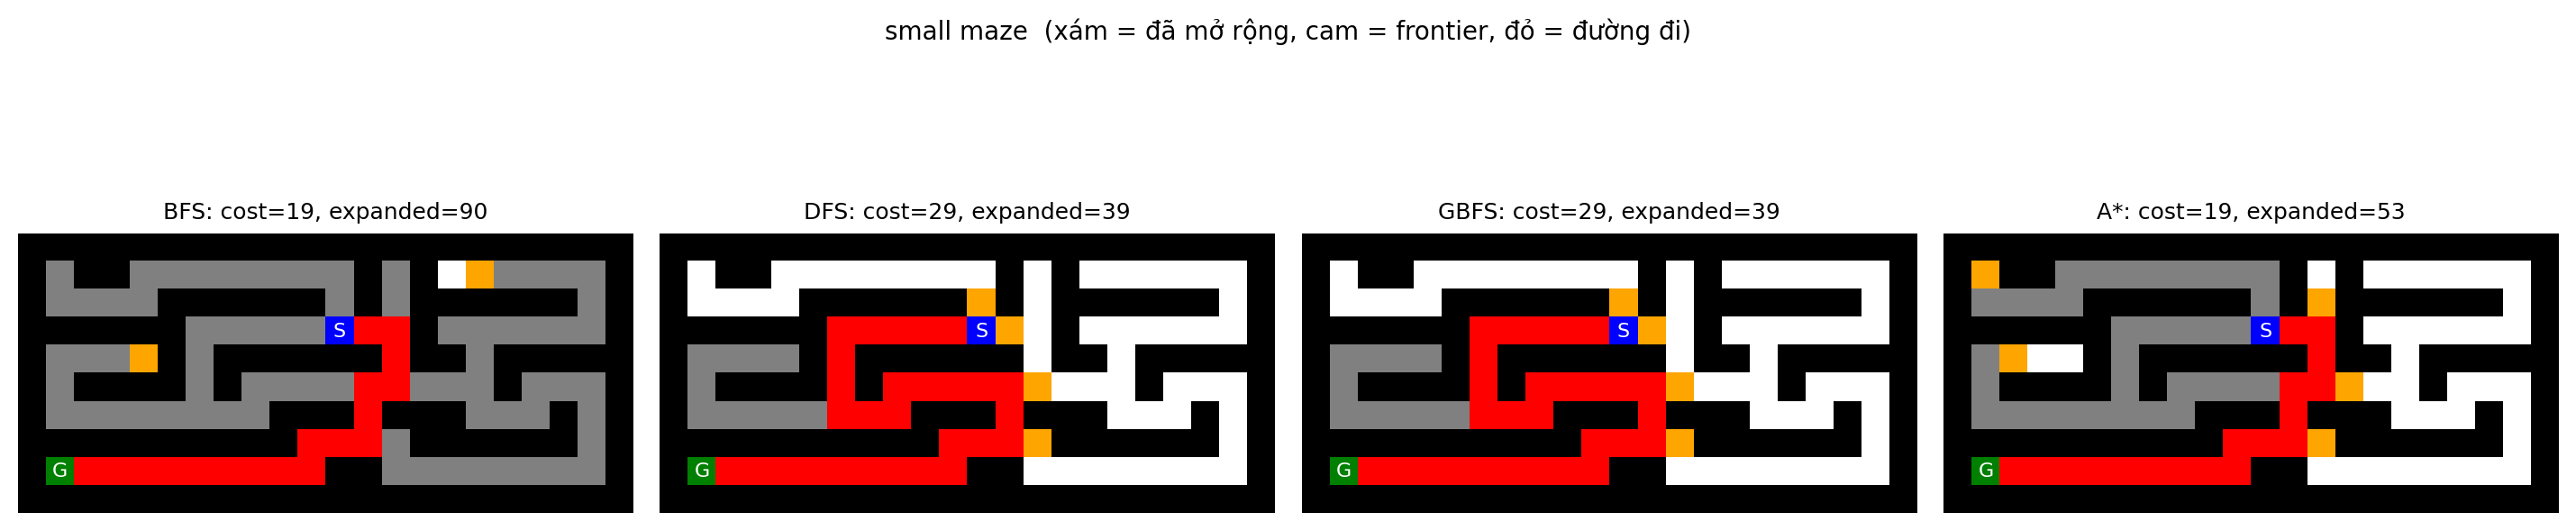

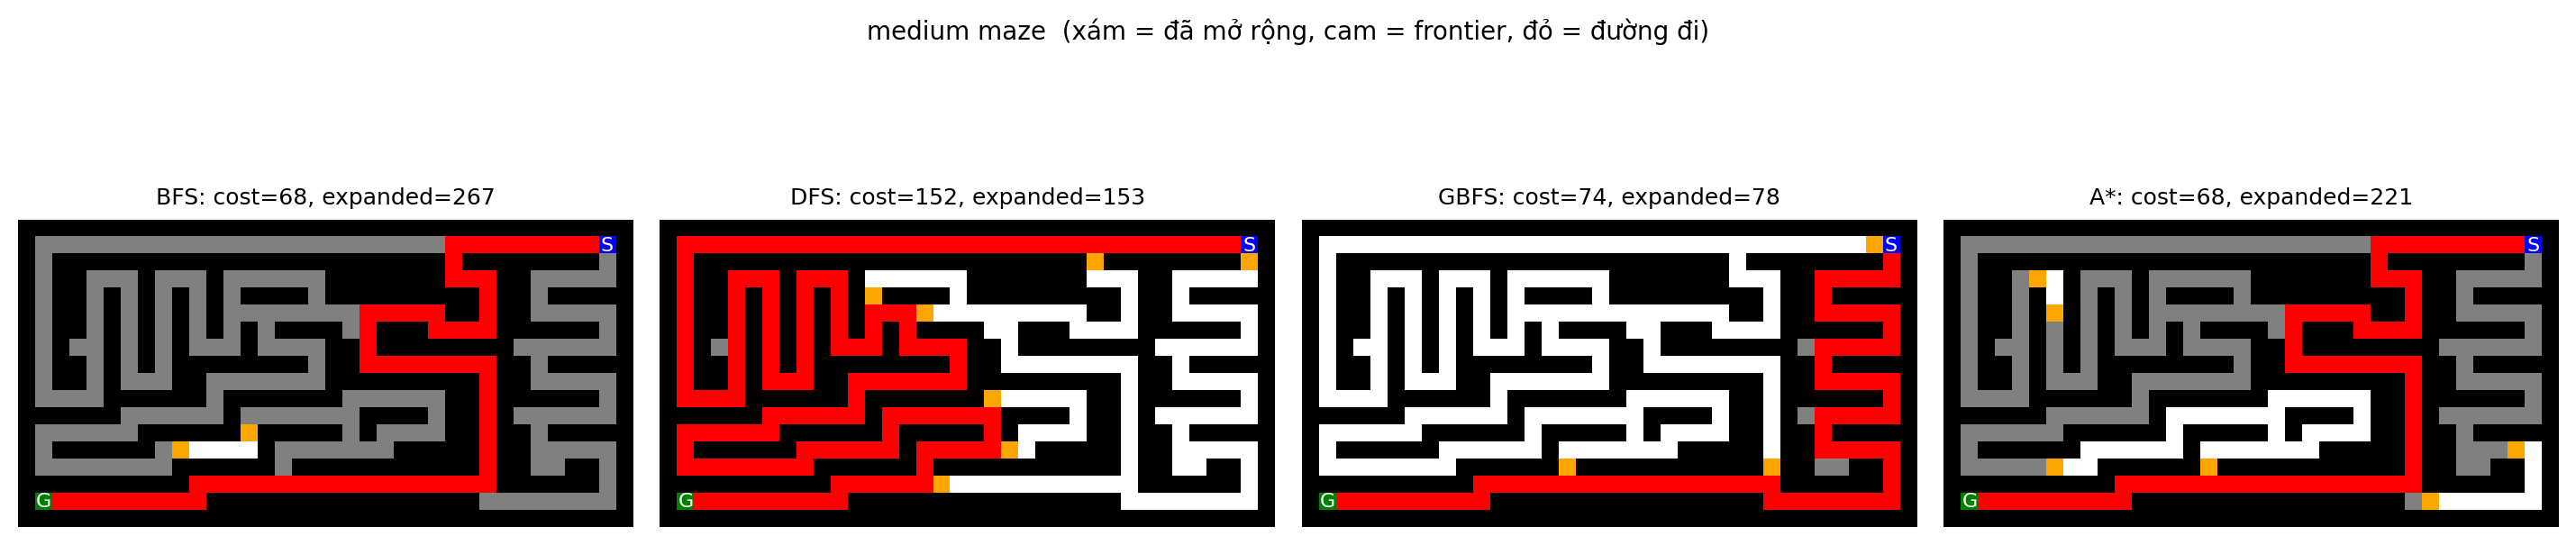

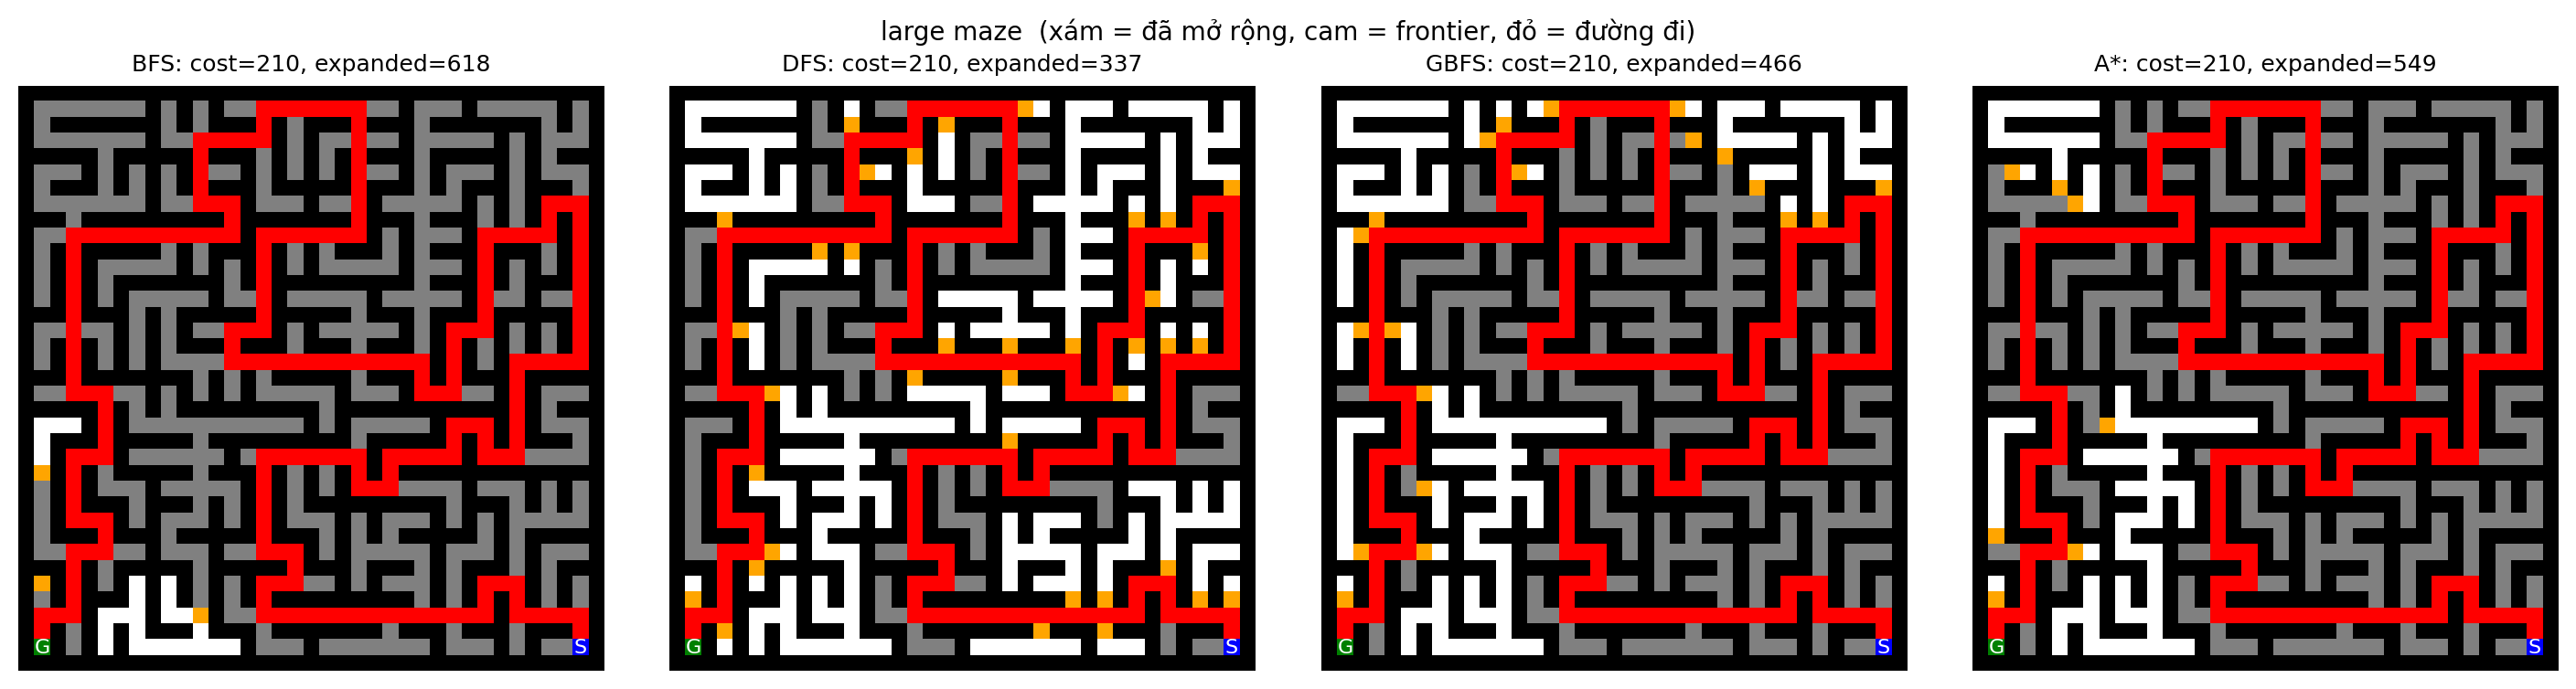

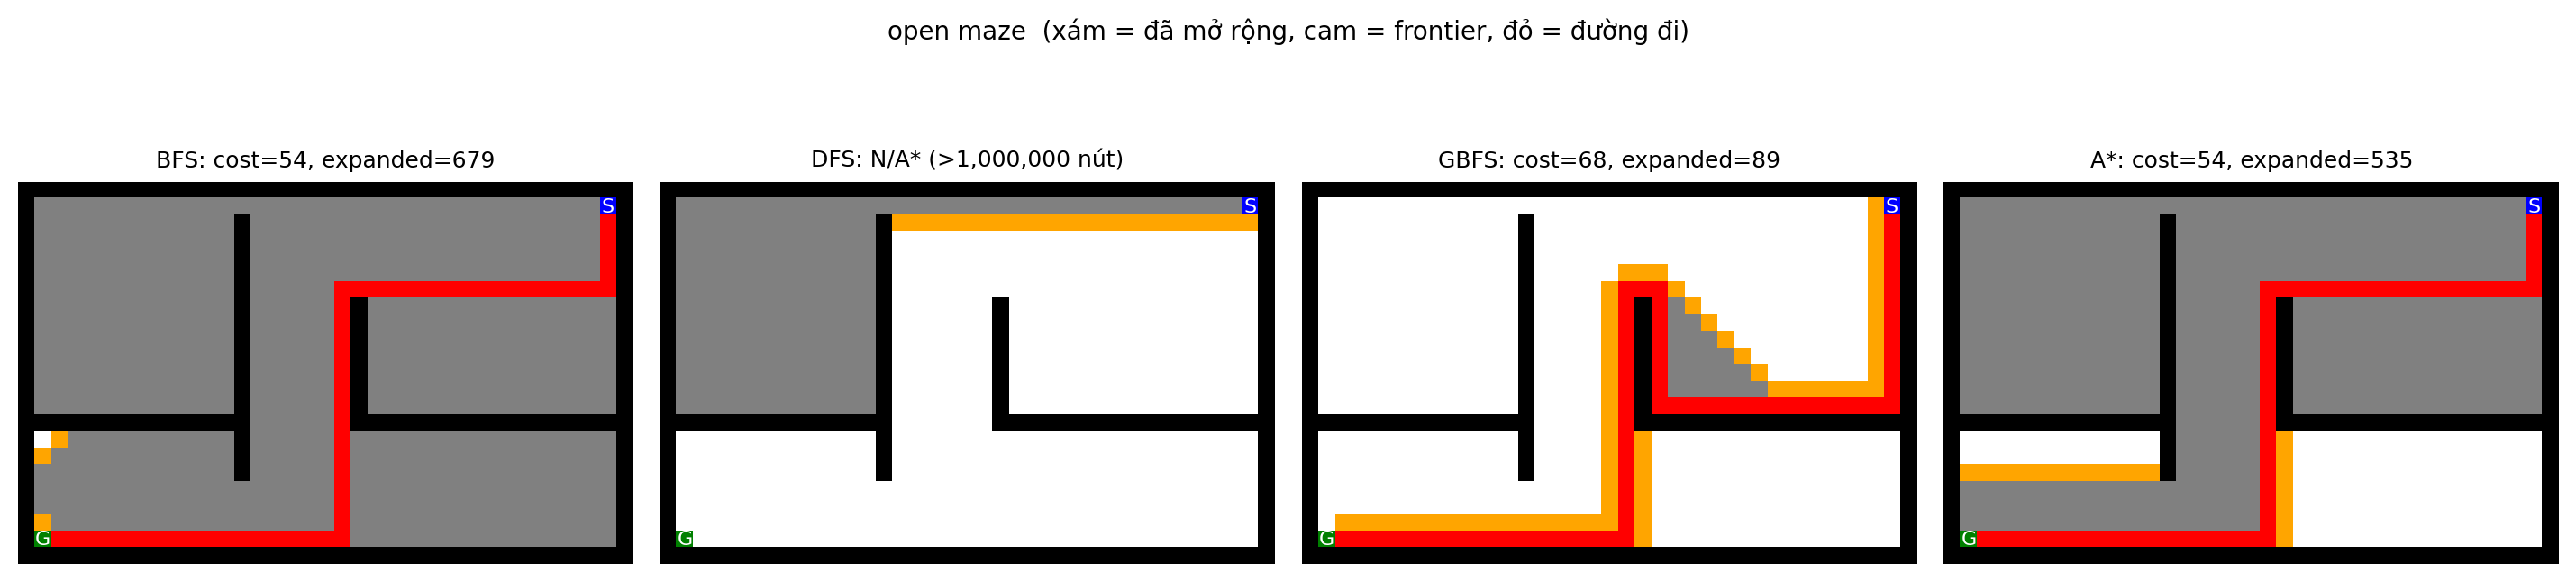

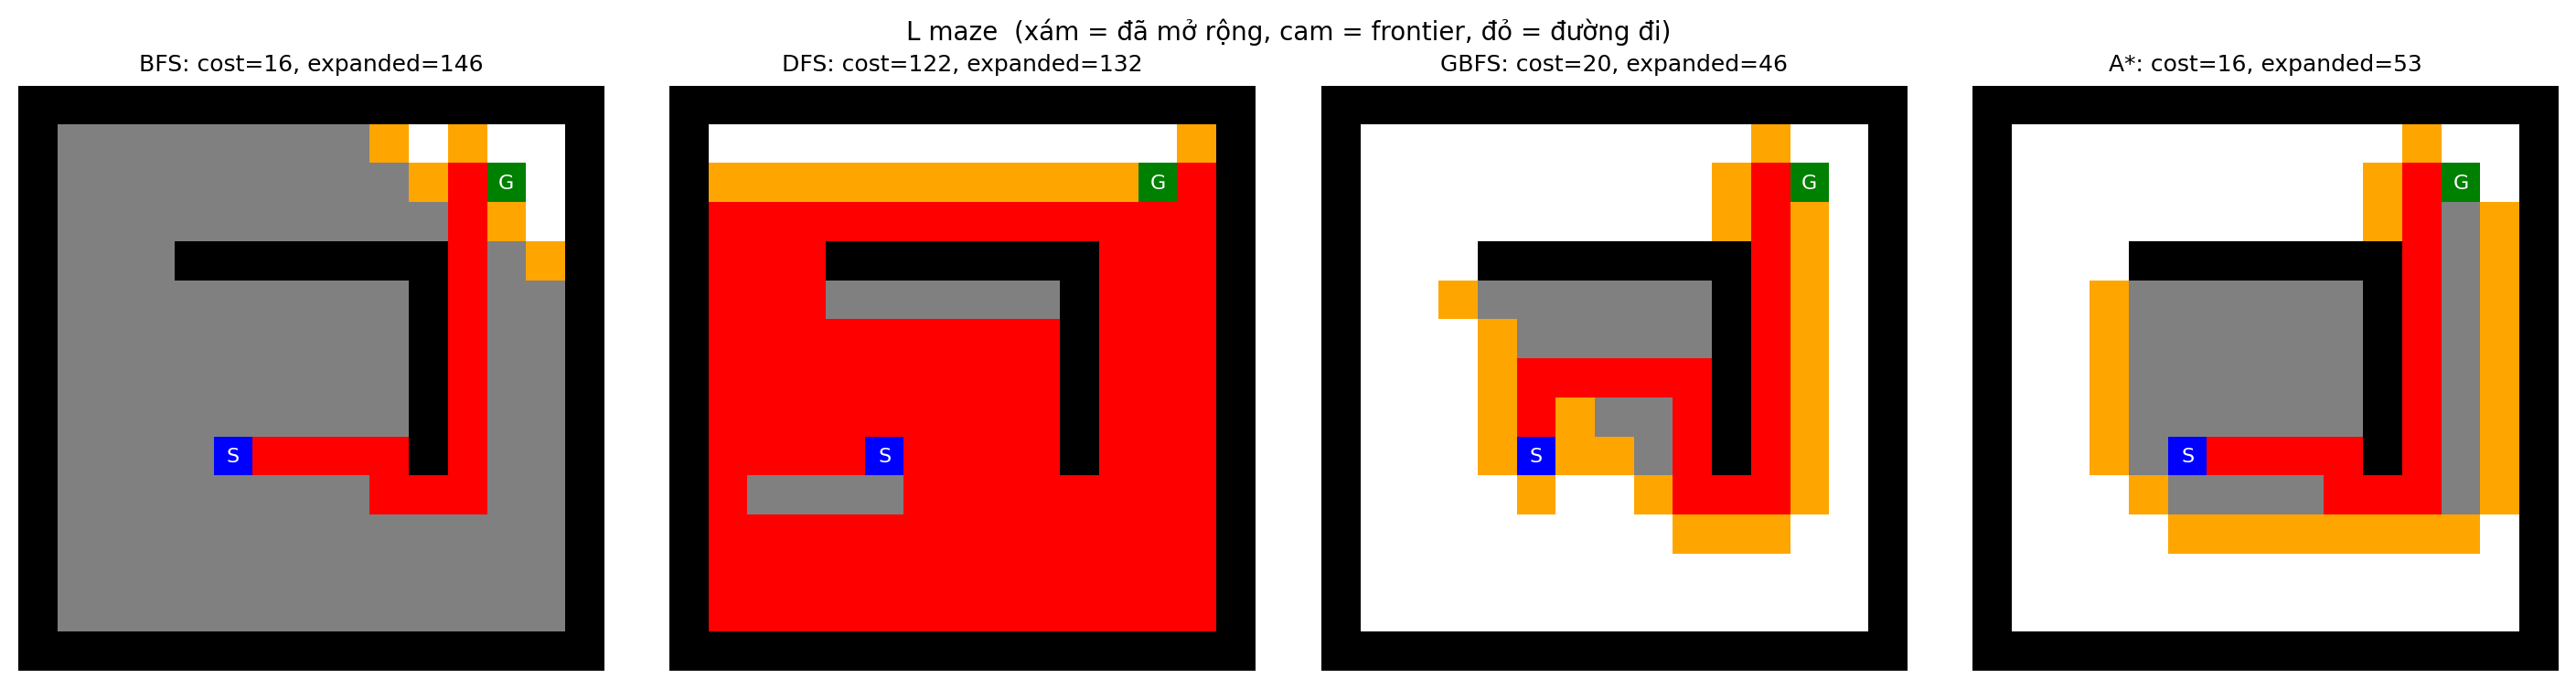

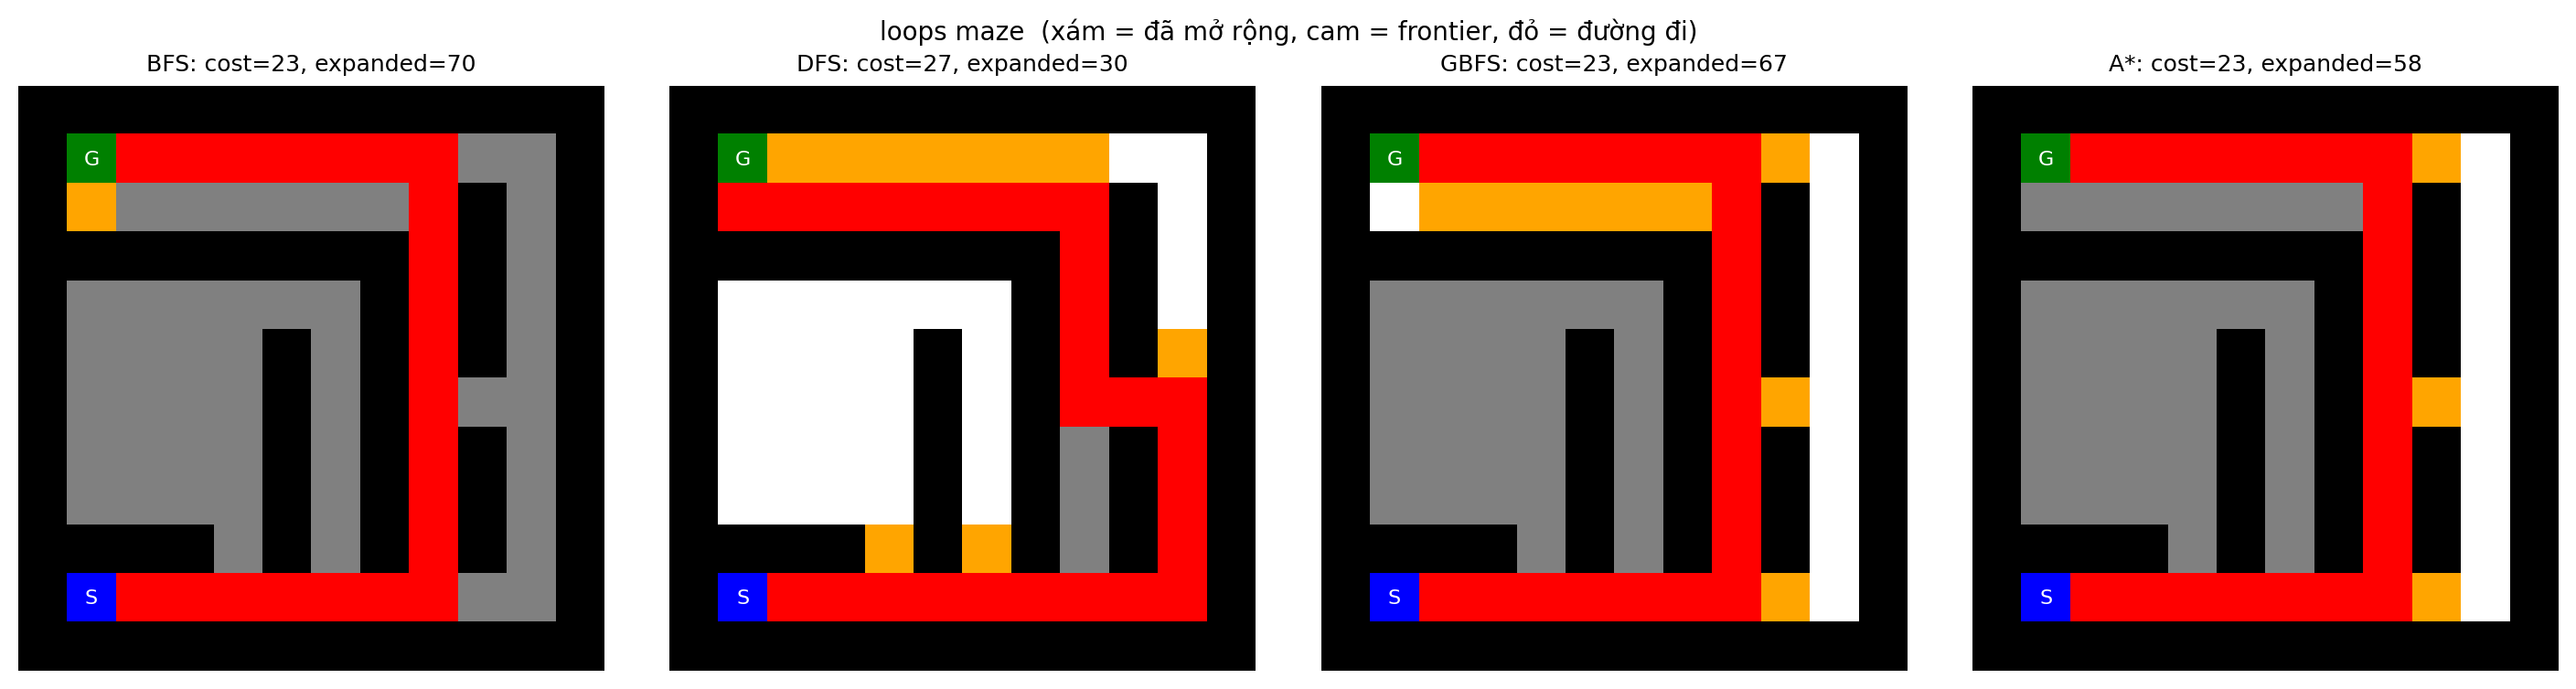

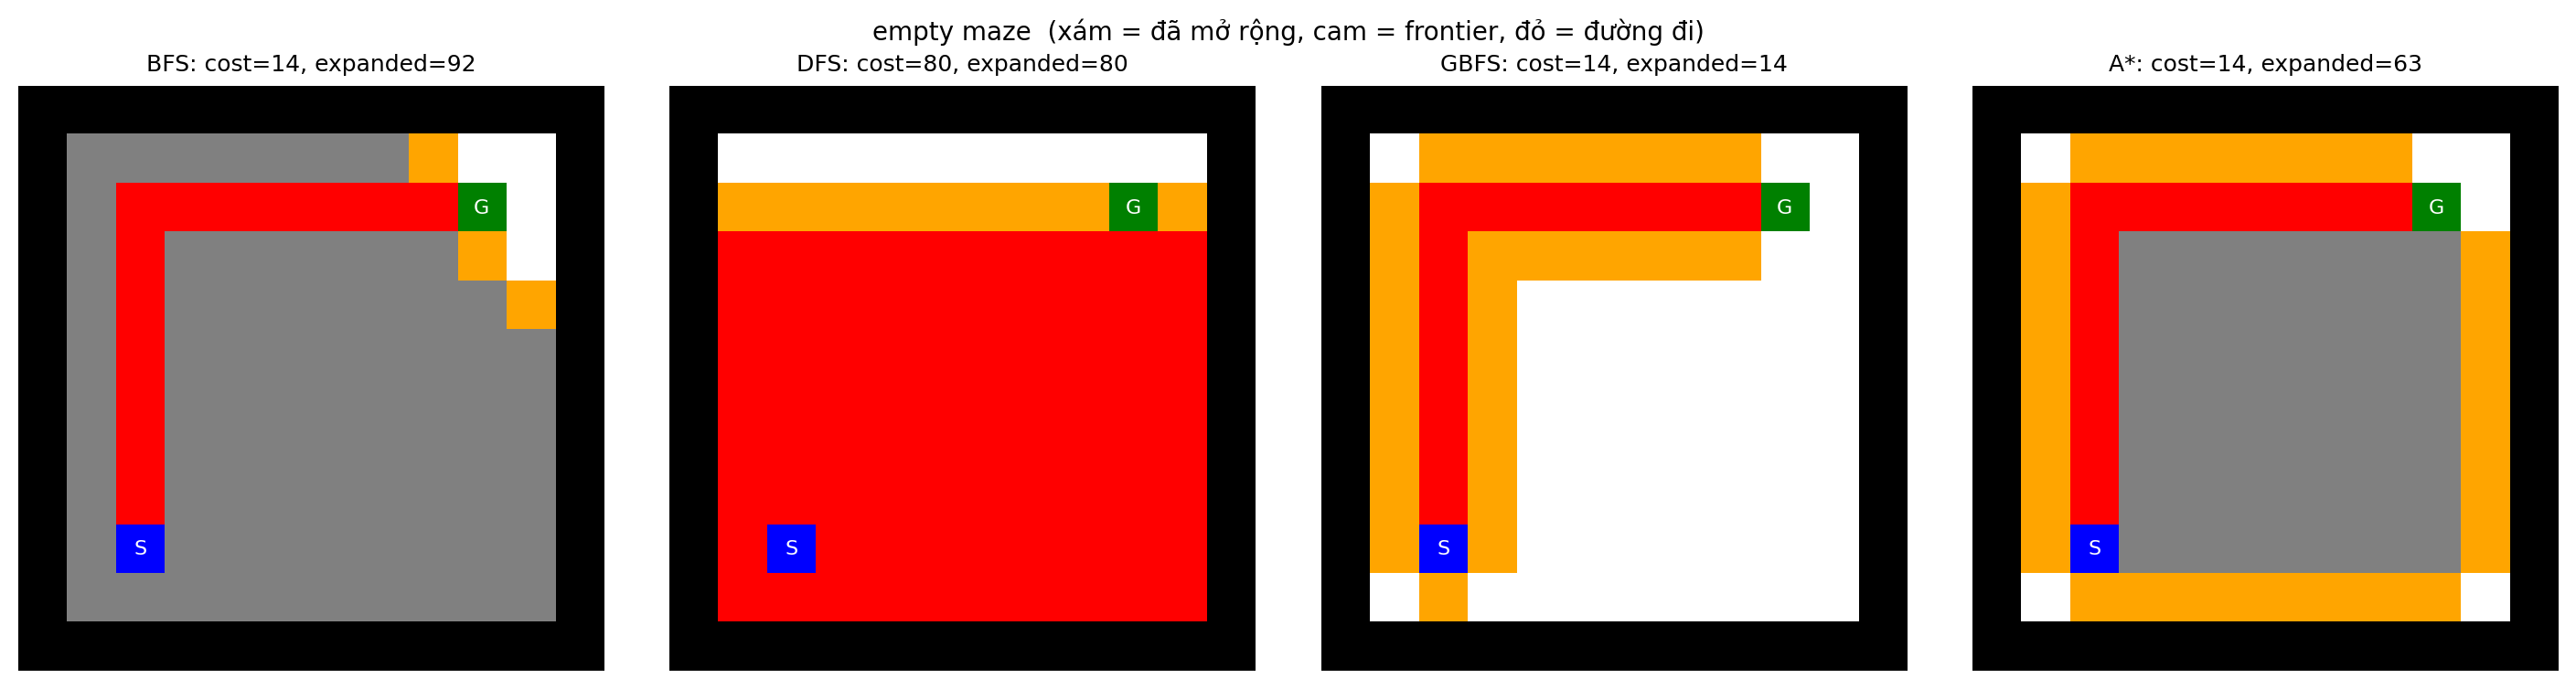

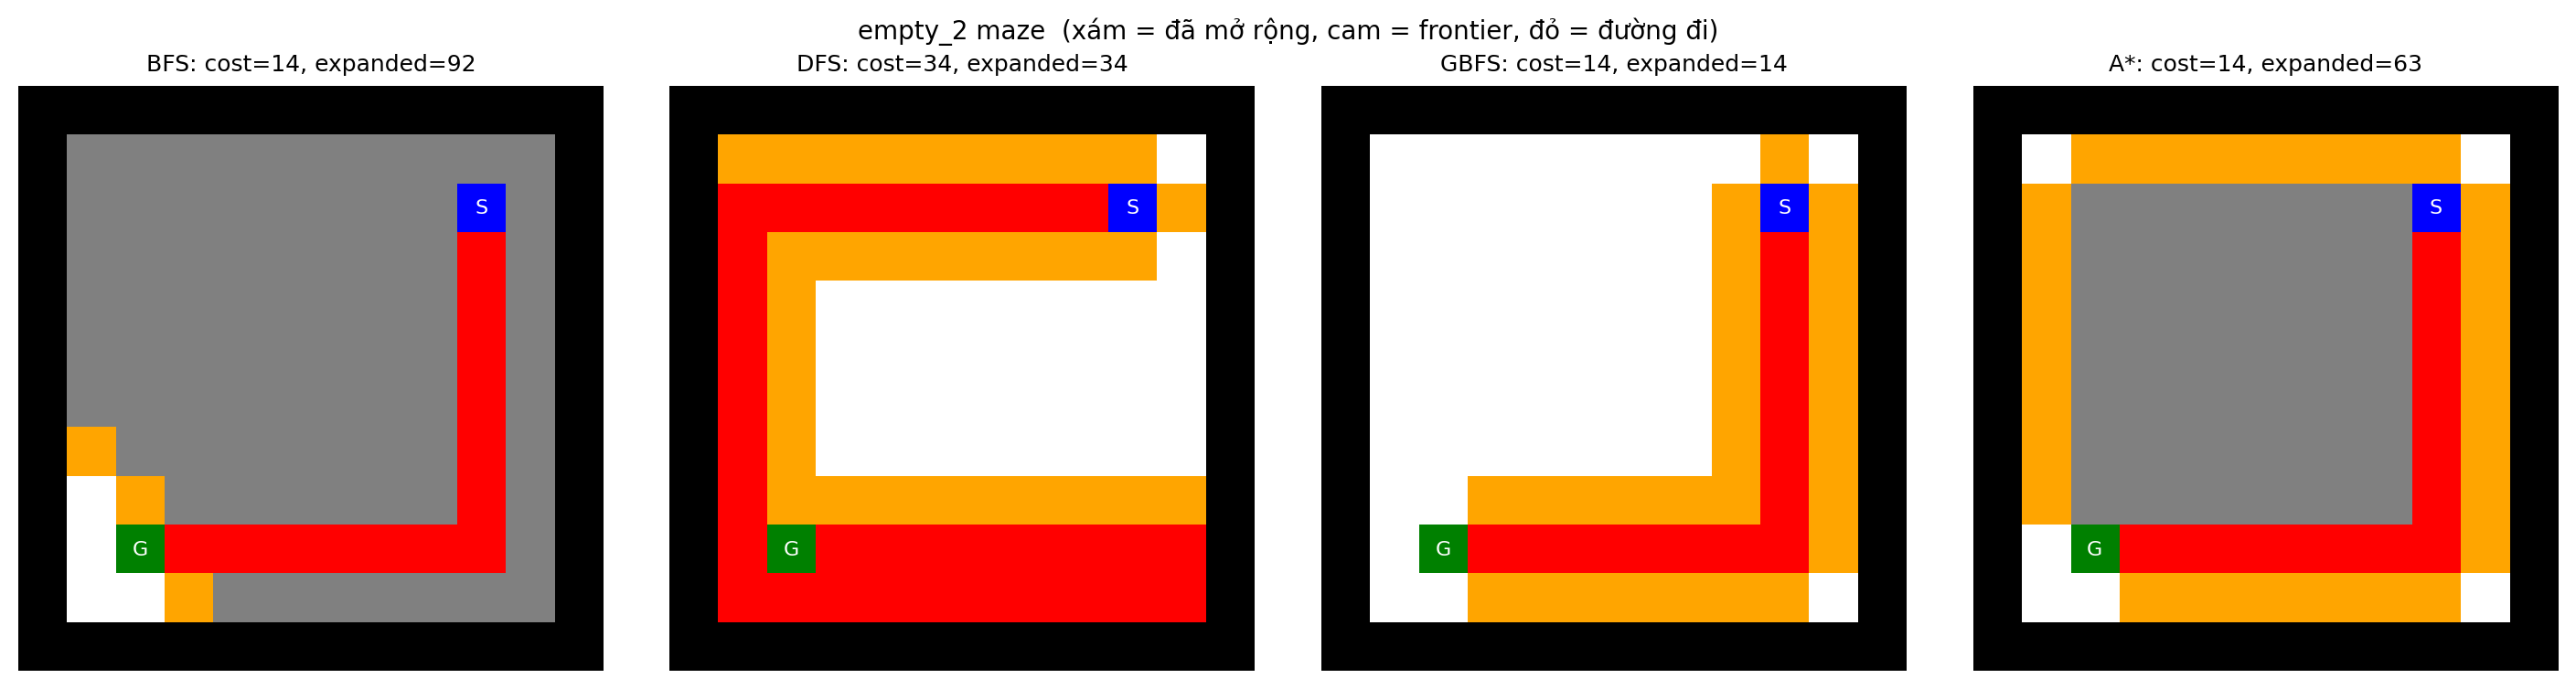

In [130]:
# Hiển thị lời giải trên từng mê cung (vẽ trên bản sao của bản đồ)
for m in mazes_dict:
    plot_maze_results(m, ["BFS", "DFS", "GBFS", "A*"])

Các bảng ở trên là bảng kết quả cho từng mê cung (cột *max # nodes in memory* là số nút tối đa cùng tồn tại trong bộ nhớ: với BFS/GBFS/A* là kích thước `reached`, với DFS là các nút frontier cộng tổ tiên của chúng, đếm bằng cơ chế `release`).

**Chú thích `N/A*`:** thuật toán không tìm ra lời giải trong ngưỡng an toàn `MAX_EXPANSIONS = 1,000,000` lần mở rộng nút. Với DFS ở open maze, đây là hậu quả của việc chỉ có cycle check mà không có `reached` (xem thảo luận ở Task 2). Thời gian chạy (ms) đo một lần trên máy chạy notebook nên chỉ mang tính tham khảo.

Present the results as using charts (see [Python Code Examples/charts and tables](../HOWTOs/charts_and_tables.ipynb)).

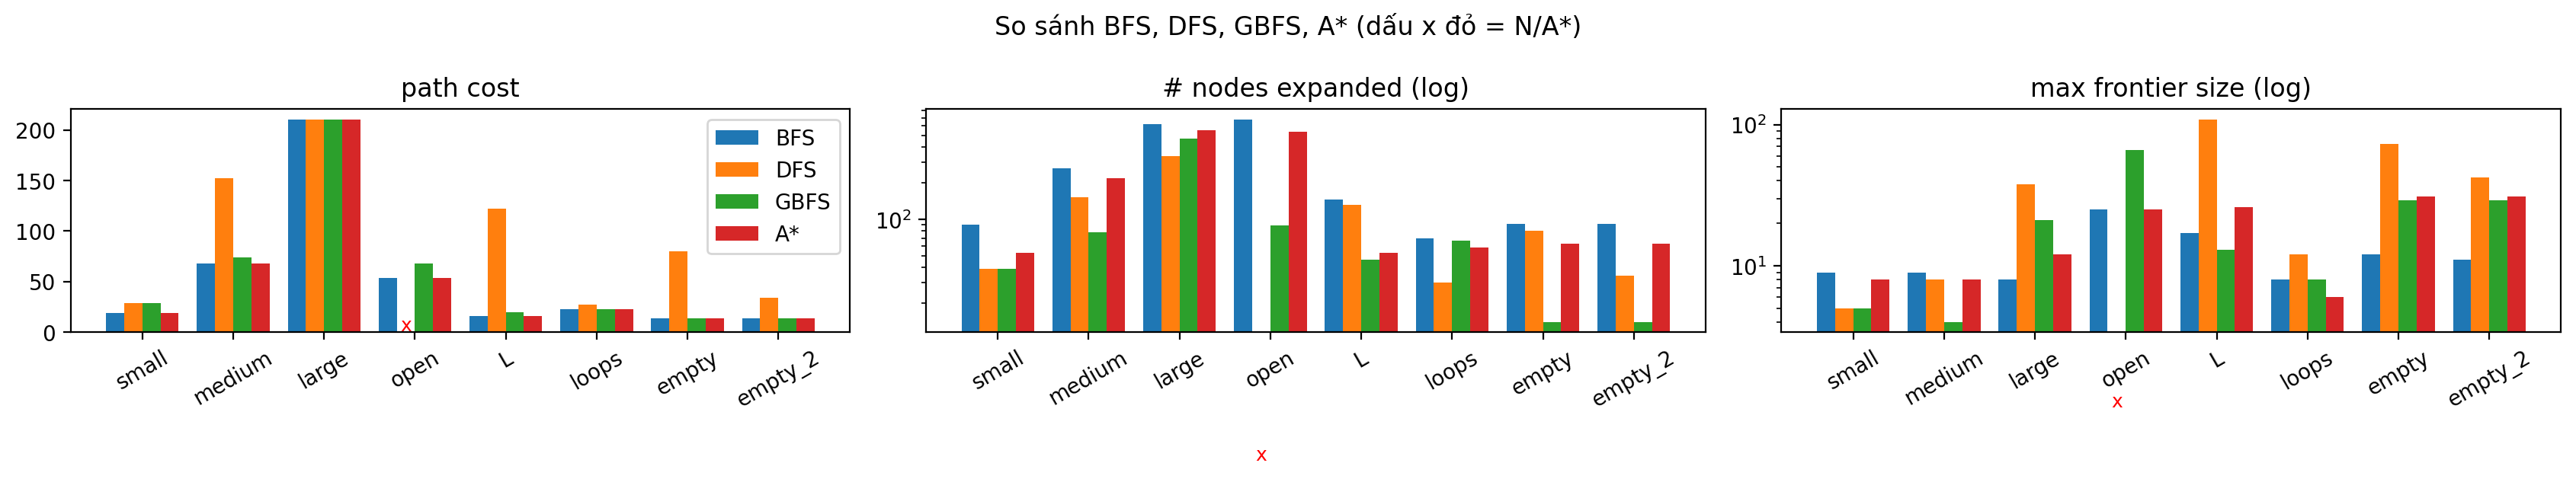

In [131]:
def plot_metrics(df, algo_names, title=""):
    """Biểu đồ cột nhóm: mỗi nhóm là một mê cung, mỗi cột là một thuật toán. N/A* hiển thị bằng dấu x."""
    metrics = [("path cost", False), ("# nodes expanded", True), ("max frontier size", True)]
    mazes_ = list(dict.fromkeys(df["maze"]))
    x = np.arange(len(mazes_)); w = 0.8 / len(algo_names)
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
    for ax, (col, log) in zip(axes, metrics):
        for i, a in enumerate(algo_names):
            sub = df[df["algorithm"] == a].set_index("maze").reindex(mazes_)
            vals = sub[col].values.astype(float)
            ax.bar(x + i * w - 0.4 + w / 2, np.nan_to_num(vals, nan=0), w, label=a)
            for xi, v in zip(x + i * w - 0.4 + w / 2, vals):
                if np.isnan(v): ax.text(xi, 1, "x", ha="center", color="red", fontsize=9)
        ax.set_xticks(x); ax.set_xticklabels(mazes_, rotation=30)
        ax.set_title(col + (" (log)" if log else ""))
        if log: ax.set_yscale("log")
    axes[0].legend(); fig.suptitle(title); plt.tight_layout(); plt.show()

plot_metrics(df4, ["BFS", "DFS", "GBFS", "A*"], "So sánh BFS, DFS, GBFS, A* (dấu x đỏ = N/A*)")

Discuss the most important lessons you have learned from implementing the different search strategies.

**Những bài học rút ra được**

1. **BFS và A\* tối ưu, DFS và GBFS thì không.** Ở medium maze, BFS và A\* đều ra đường 68 bước, còn DFS ra 152 bước và GBFS ra 74 bước. Ở empty maze, DFS đi tới 80 bước trong khi đích chỉ cách 14 bước. Riêng large maze thì cả DFS và GBFS tình cờ ra đúng 210, vì mê cung toàn hành lang hẹp nên gần như chỉ có một đường.
2. **Heuristic giúp giảm rất nhiều việc phải làm.** A\* mở rộng ít nút hơn BFS ở mọi mê cung mà vẫn tối ưu (empty: 63 so với 92; large: 549 so với 618, giảm ít vì đường đi phải vòng xa khỏi đích). GBFS mở rộng ít nhất (empty maze chỉ đúng 14 nút nằm trên đường đi) nhưng dễ bị tường đánh lừa (L maze, open maze, medium).
3. **Kiểm tra trạng thái lặp (`reached`) quyết định hiệu năng.** BFS/GBFS/A\* có `reached` nên mỗi ô mở rộng không quá vài lần. DFS chỉ có cycle check nên có thể duyệt lại một ô theo số đường đi, tăng theo hàm mũ: ở open maze DFS không xong trong 1,000,000 lần mở rộng, còn BFS chỉ cần 679.
4. **Bộ nhớ và thời gian đánh đổi nhau.** BFS giữ gần như toàn bộ nút (bộ nhớ lớn, thời gian ít). IDS giữ rất ít nút nhưng làm lại nhiều việc: ở empty maze IDS mở rộng 297,368 nút (BFS: 92) nhưng chỉ có tối đa 33 nút cùng lúc trong bộ nhớ (BFS: 95); ở large là 248 so với 621. Lưu ý *frontier* của DFS/IDS không nhỏ hơn BFS (large: 38 so với 8), lợi thế nằm ở tổng số nút phải giữ.
5. **Cấu trúc mê cung ảnh hưởng nhiều.** Với mê cung toàn hành lang hẹp (small, medium, large) các thuật toán khá giống nhau vì ít lựa chọn. Ở vùng trống (open, empty, loops) sự khác biệt rất lớn.
6. **Chi tiết cài đặt quan trọng.** BFS kiểm tra đích lúc sinh nút thì được, nhưng A\* phải kiểm tra lúc **lấy nút ra** thì mới đảm bảo tối ưu. Hàng đợi ưu tiên cần số thứ tự phá hòa, và phải thêm lại nút khi tìm được đường rẻ hơn tới ô đã `reached`. Ngoài ra không ghi thông tin tìm kiếm vào bản đồ: mọi thứ nằm trong cây nút, `frontier`, `reached`, và chỉ vẽ lên một **bản sao** của bản đồ sau khi tìm xong.

### Extra: Heuristic Manhattan và Euclidean

Đề bài yêu cầu so sánh hai heuristic cho GBFS và A\*. Cả hai đều không bao giờ đánh giá quá cao khoảng cách thật, nhưng khi chỉ đi được lên/xuống/trái/phải thì Manhattan sát với khoảng cách thật hơn.

In [132]:
rows = []
for name, m in mazes_dict.items():
    s, gs = get_problem(m)
    for alg_name, alg in {"GBFS": gbfs, "A*": astar}.items():
        for h in ["manhattan", "euclidean"]:
            r = alg(m, s, gs, heuristic=h)
            rows.append({"maze": name, "algorithm": alg_name, "heuristic": h,
                         "path cost": r["cost"], "expanded": r["expanded"]})
pd.DataFrame(rows).pivot(index=["maze", "algorithm"], columns="heuristic", values=["path cost", "expanded"])

path cost            expanded          
heuristic         euclidean manhattan euclidean manhattan
maze    algorithm                                        
L       A*               16        16        70        53
        GBFS             18        20        39        46
empty   A*               14        14        74        63
        GBFS             14        14        14        14
empty_2 A*               14        14        74        63
        GBFS             14        14        14        14
large   A*              210       210       557       549
        GBFS            210       210       471       466
loops   A*               23        23        64        58
        GBFS             23        23        64        67
medium  A*               68        68       226       221
        GBFS            152        74       159        78
open    A*               54        54       550       535
        GBFS             54        68        54        89
small   A*               19        19        56        53
        GBFS             29        29        39        39

**Nhận xét.** Với A\*, cả hai heuristic đều cho đường tối ưu (đều admissible), nhưng Euclidean mở rộng nhiều nút hơn ở mọi mê cung (open: 550 so với 535, L: 70 so với 53, empty: 74 so với 63). Lý do là khi chỉ đi 4 hướng thì Euclidean đánh giá thấp khoảng cách thật hơn Manhattan, nên cắt tỉa được ít nút hơn. Với GBFS thì kết quả lẫn lộn: Euclidean ra đường ngắn hơn ở L (18 so với 20) và open (54 so với 68), nhưng tệ hơn nhiều ở medium (152 so với 74). Nhìn chung Manhattan hợp hơn với di chuyển 4 hướng, nhất là cho A\*, vì ở lưới trống nó đúng bằng khoảng cách thật.

## Advanced task: IDS and Multiple goals

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### IDS
Implement IDS (iterative deepening search) using your DFS implementation. Test IDS on the mazes above. You may run into some issues with mazes with open spaces. If you cannot resolve the issues, then report and discuss what causes the problems.

In [133]:
def ids(maze, start, goals):
    """Iterative deepening search: lặp DFS có giới hạn độ sâu l = 0, 1, 2, ... (dùng lại dfs_core ở trên).
    Số liệu (nút mở rộng, thời gian) được CỘNG DỒN qua mọi vòng lặp; độ sâu/frontier/bộ nhớ lấy giá trị lớn nhất."""
    t0 = time.perf_counter(); st = new_stats()
    limit = 0
    while True:
        res, cutoff = dfs_core(maze, start, goals, limit=limit, stats=st, t0=t0)
        if res["status"] in ("solved", "limit"):      # tìm thấy lời giải, hoặc vượt ngưỡng an toàn
            res["limit"] = limit
            return res
        if not cutoff:                                # không còn nhánh nào bị cắt -> đã duyệt hết, vô nghiệm
            res["limit"] = limit
            return res
        limit += 1


# Thêm IDS vào bộ thuật toán và chạy trên cả 8 mê cung
ALGOS["IDS"] = ids
for m in mazes_dict:
    r = run(m, "IDS")
    if r["status"] == "solved":
        validate(mazes_dict[m], r)
df_ids = summary_table(list(mazes_dict), ["IDS"])
show_table(df_ids)

,maze,algorithm,path cost,# nodes expanded,max tree depth,max # nodes in memory,max frontier size,time (ms)
0,small,IDS,19,923,19,25,6,6.2
1,medium,IDS,68,15665,68,75,8,142.69
2,large,IDS,210,60179,210,248,38,756.75
3,open,IDS,N/A*,N/A*,N/A*,N/A*,N/A*,N/A*
4,L,IDS,N/A*,N/A*,N/A*,N/A*,N/A*,N/A*
5,loops,IDS,23,60701,23,36,14,529.66
6,empty,IDS,14,297368,14,33,19,3196.93
7,empty_2,IDS,14,204382,14,39,25,2240.37


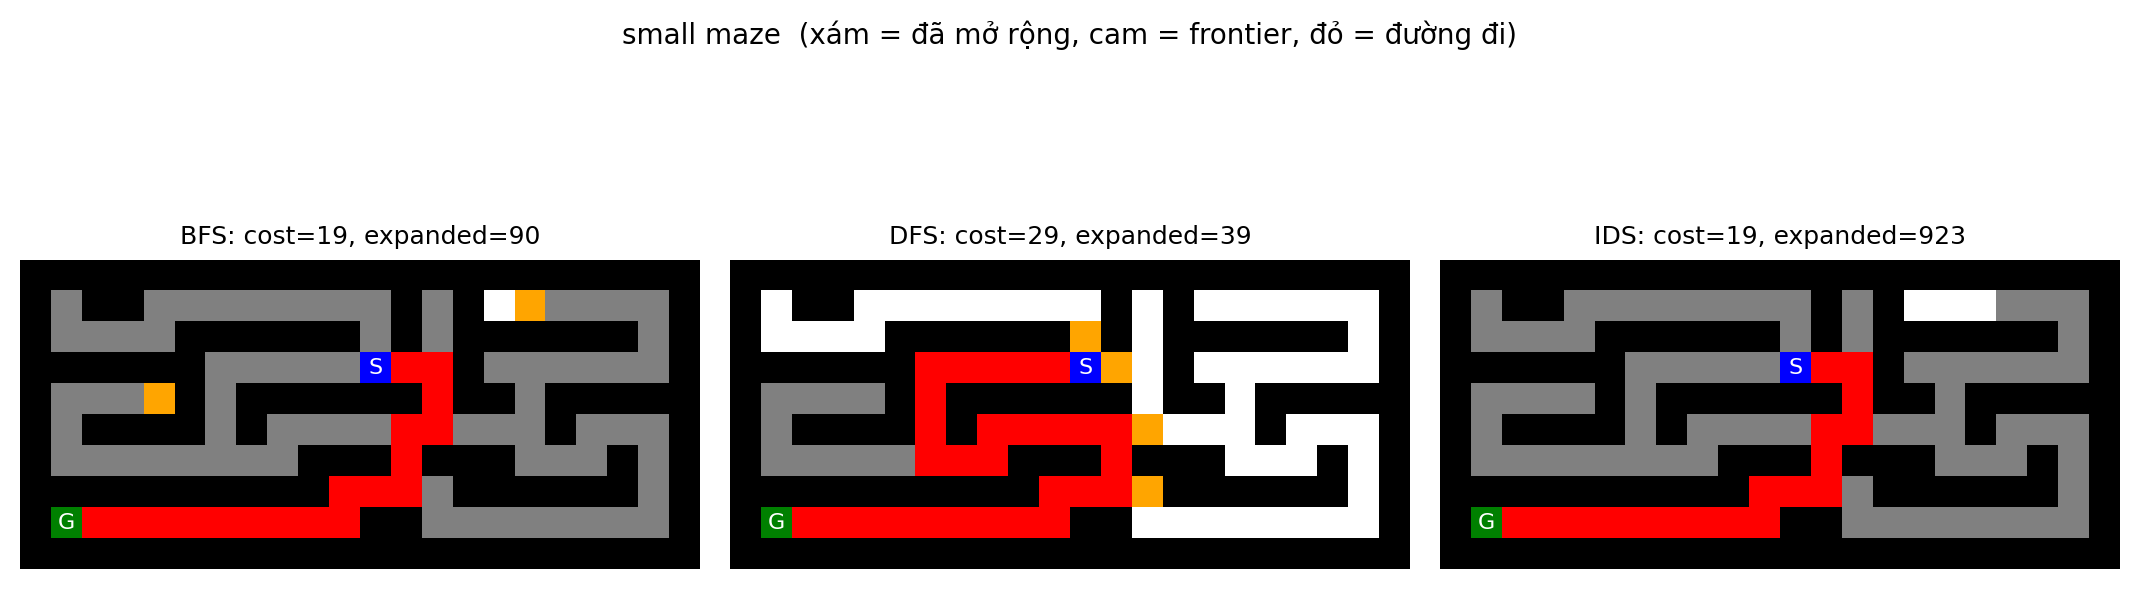

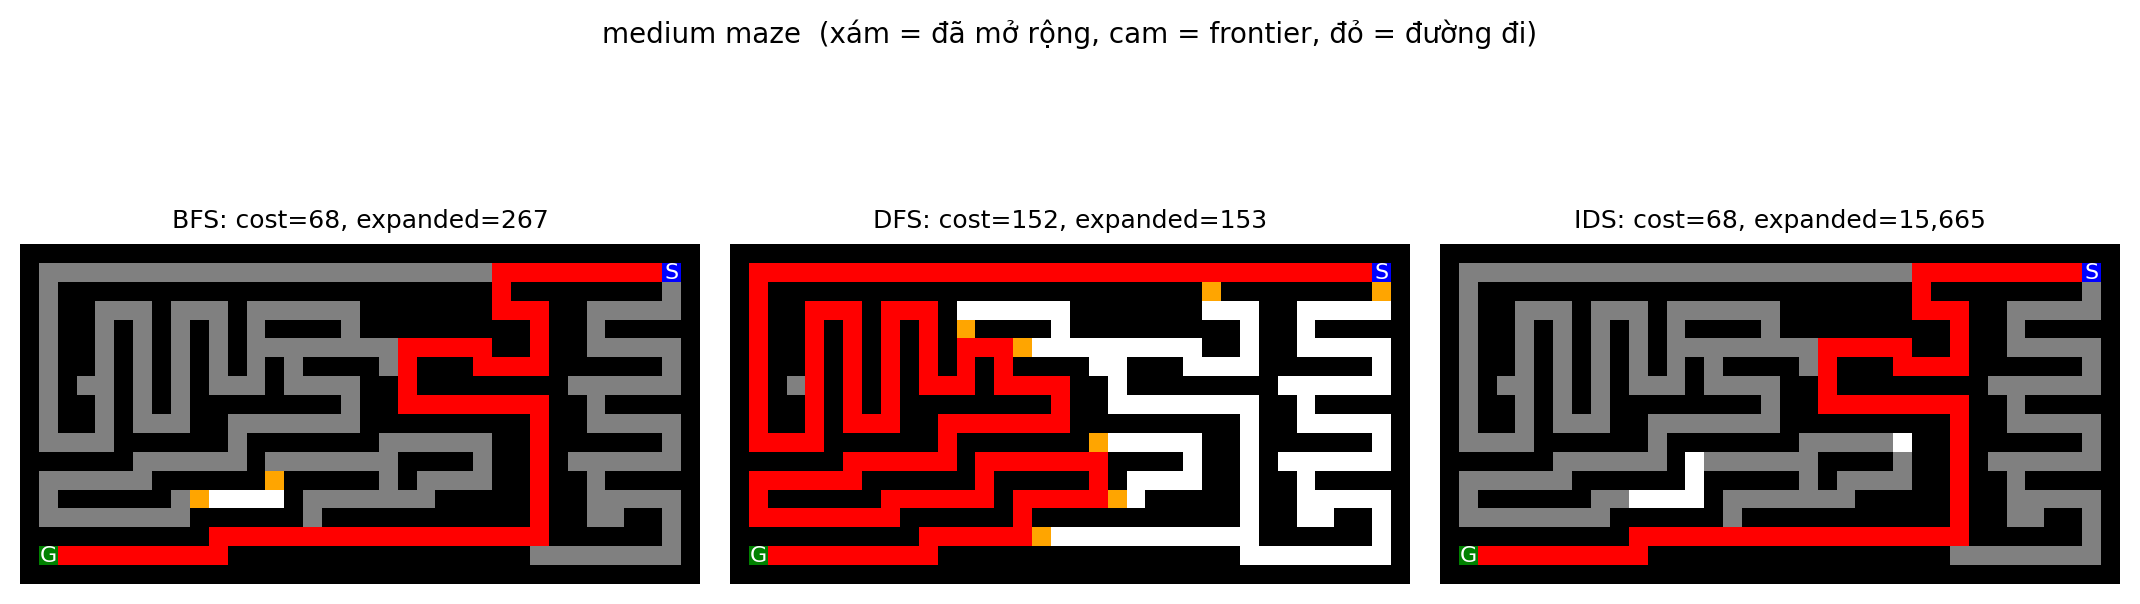

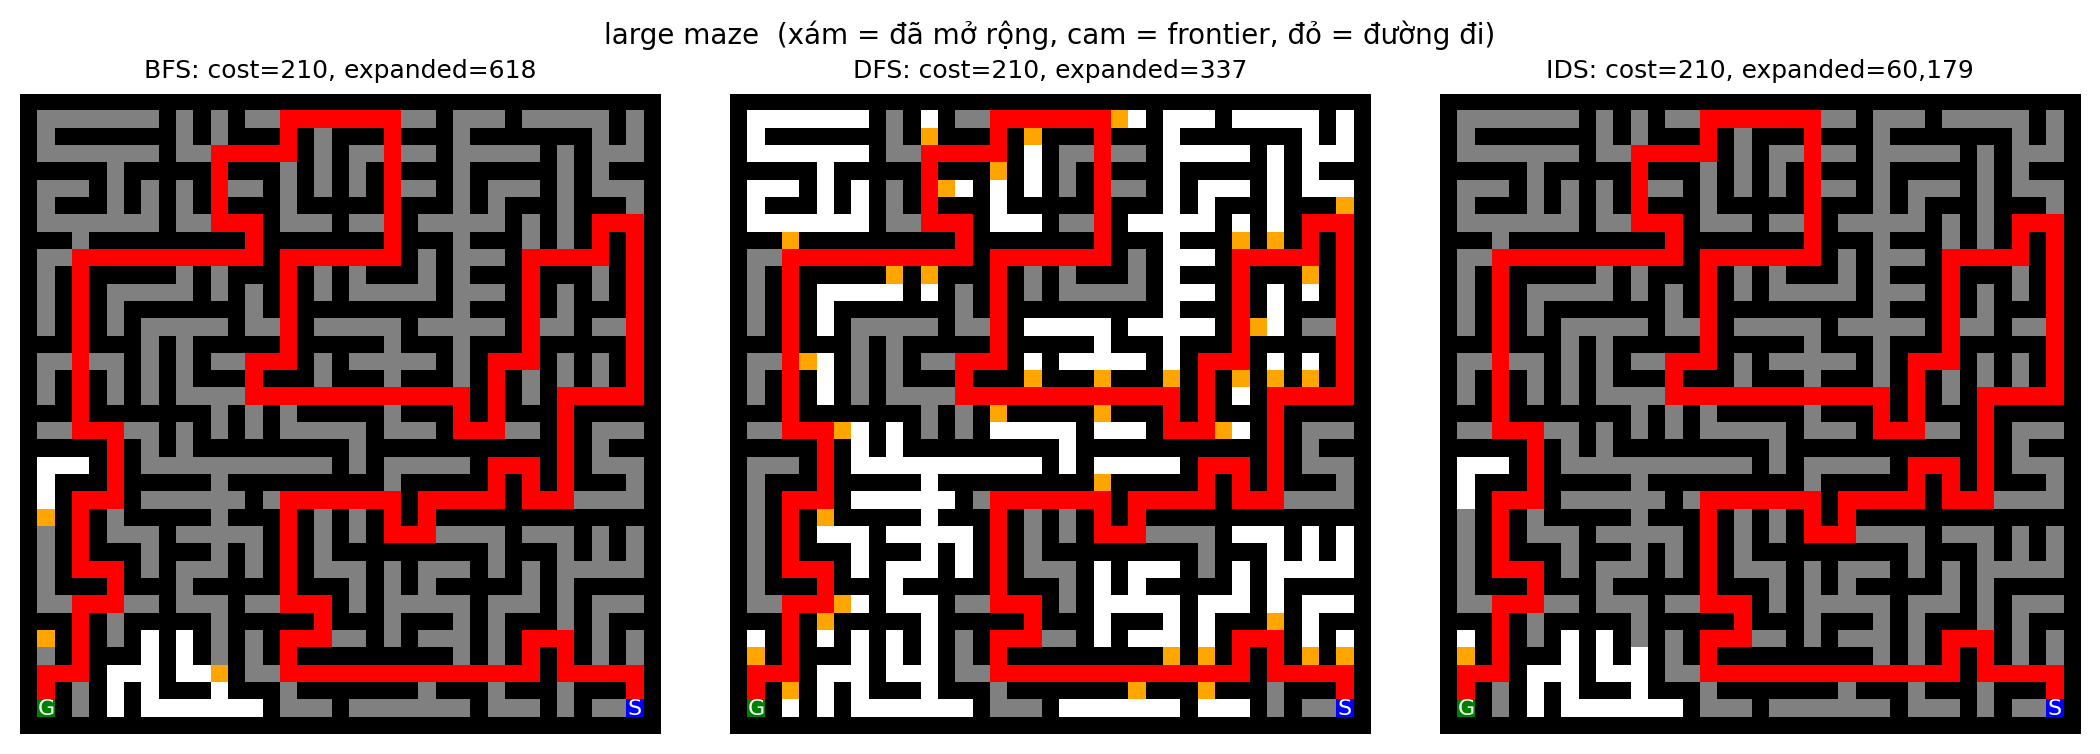

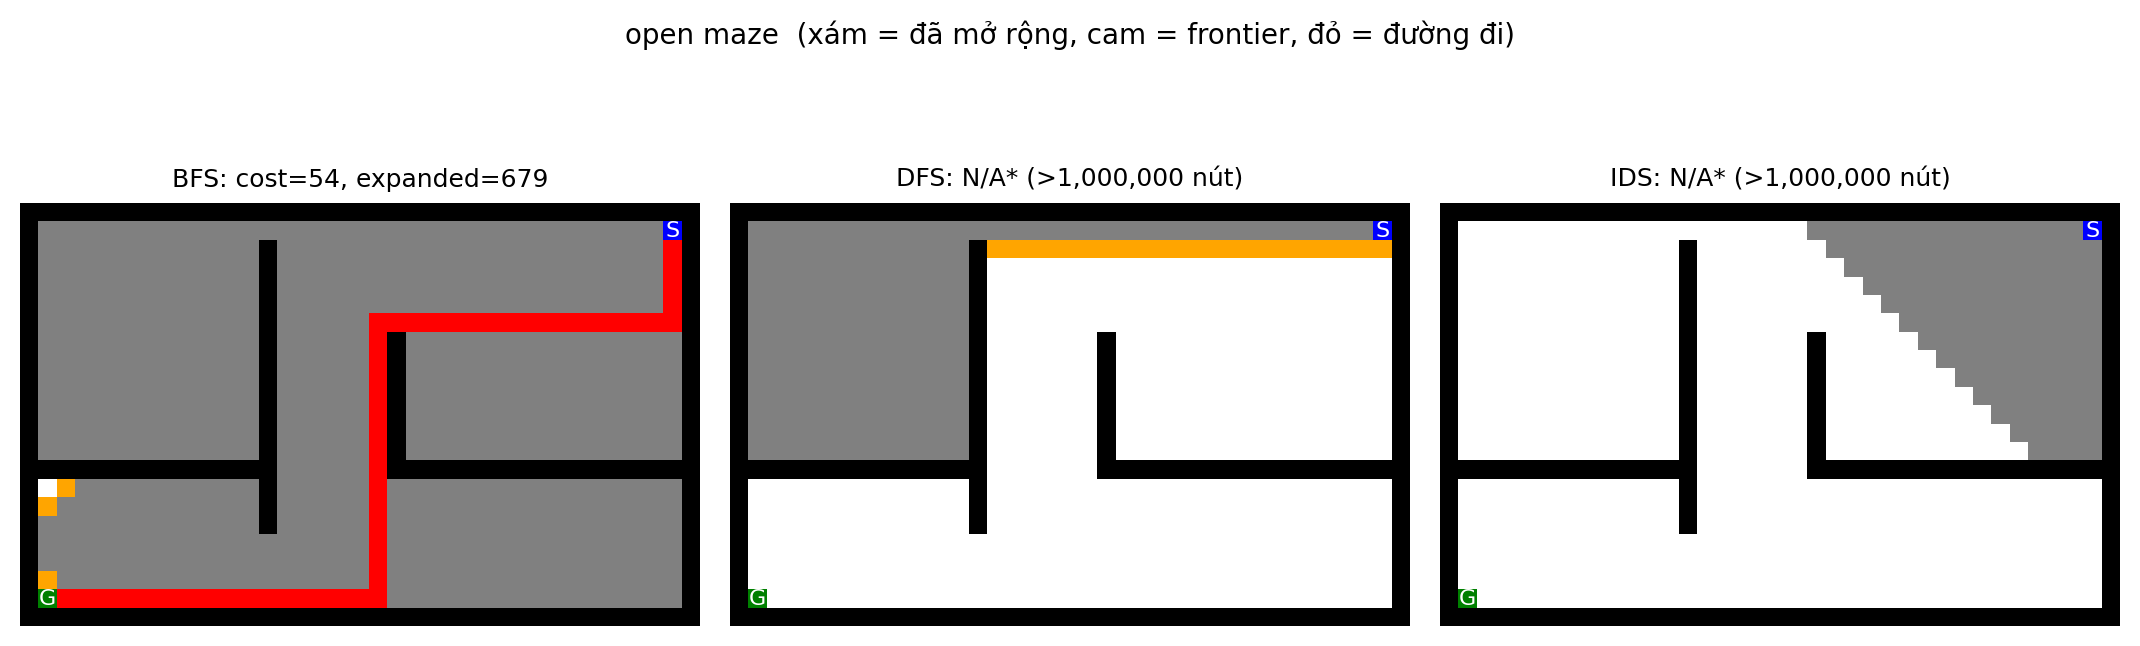

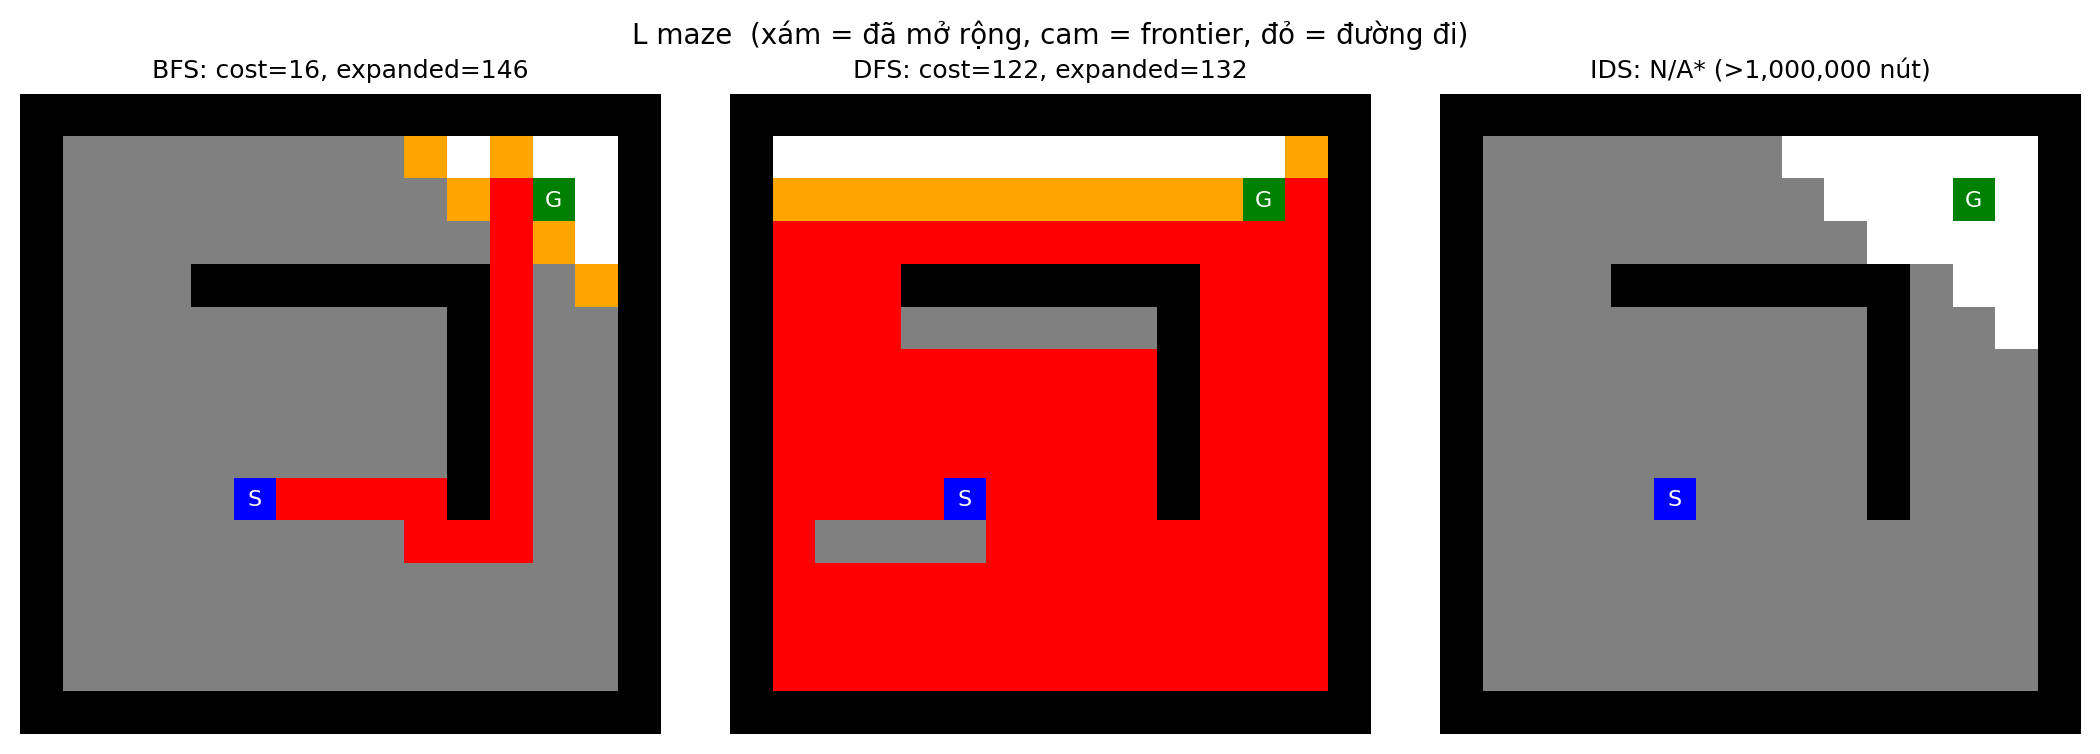

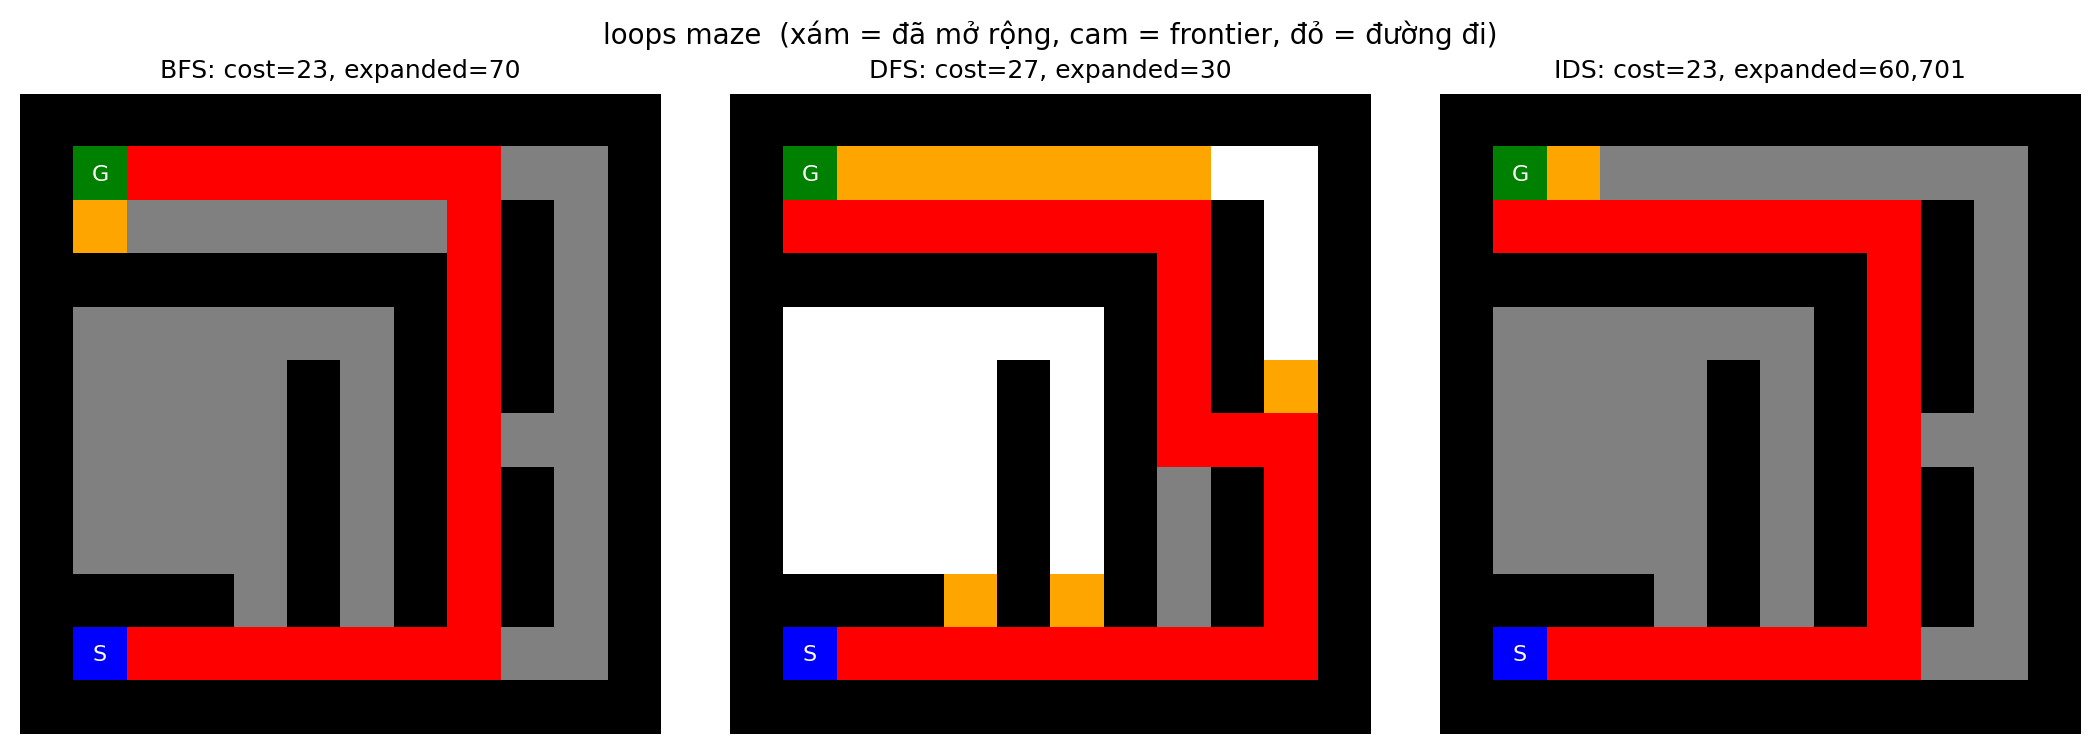

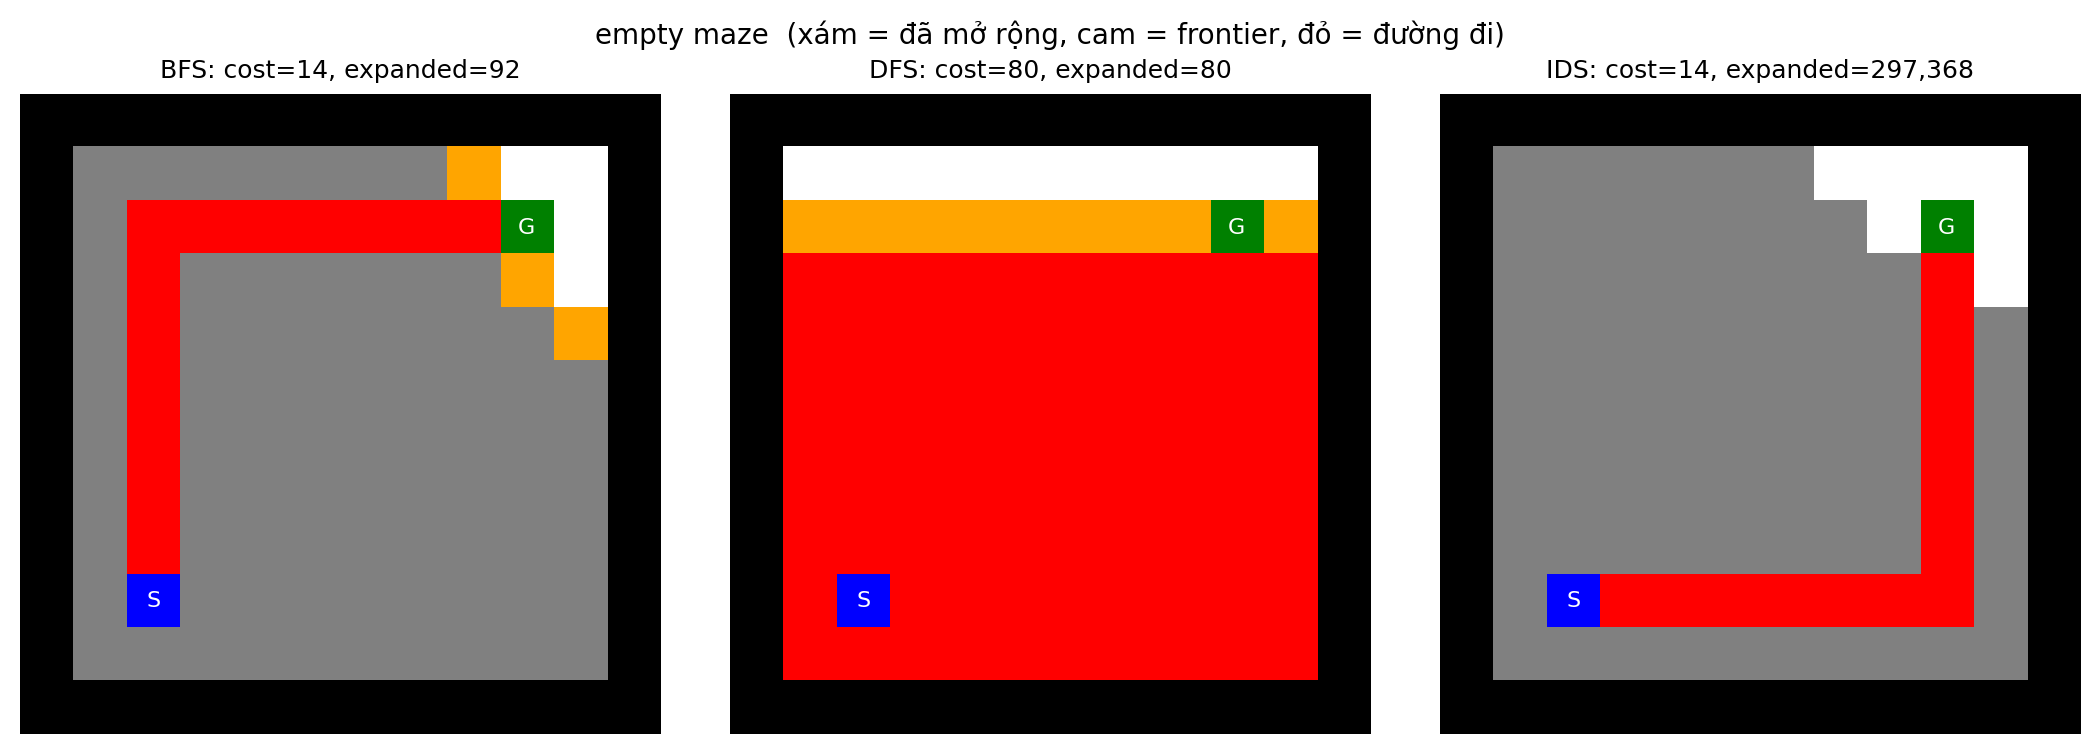

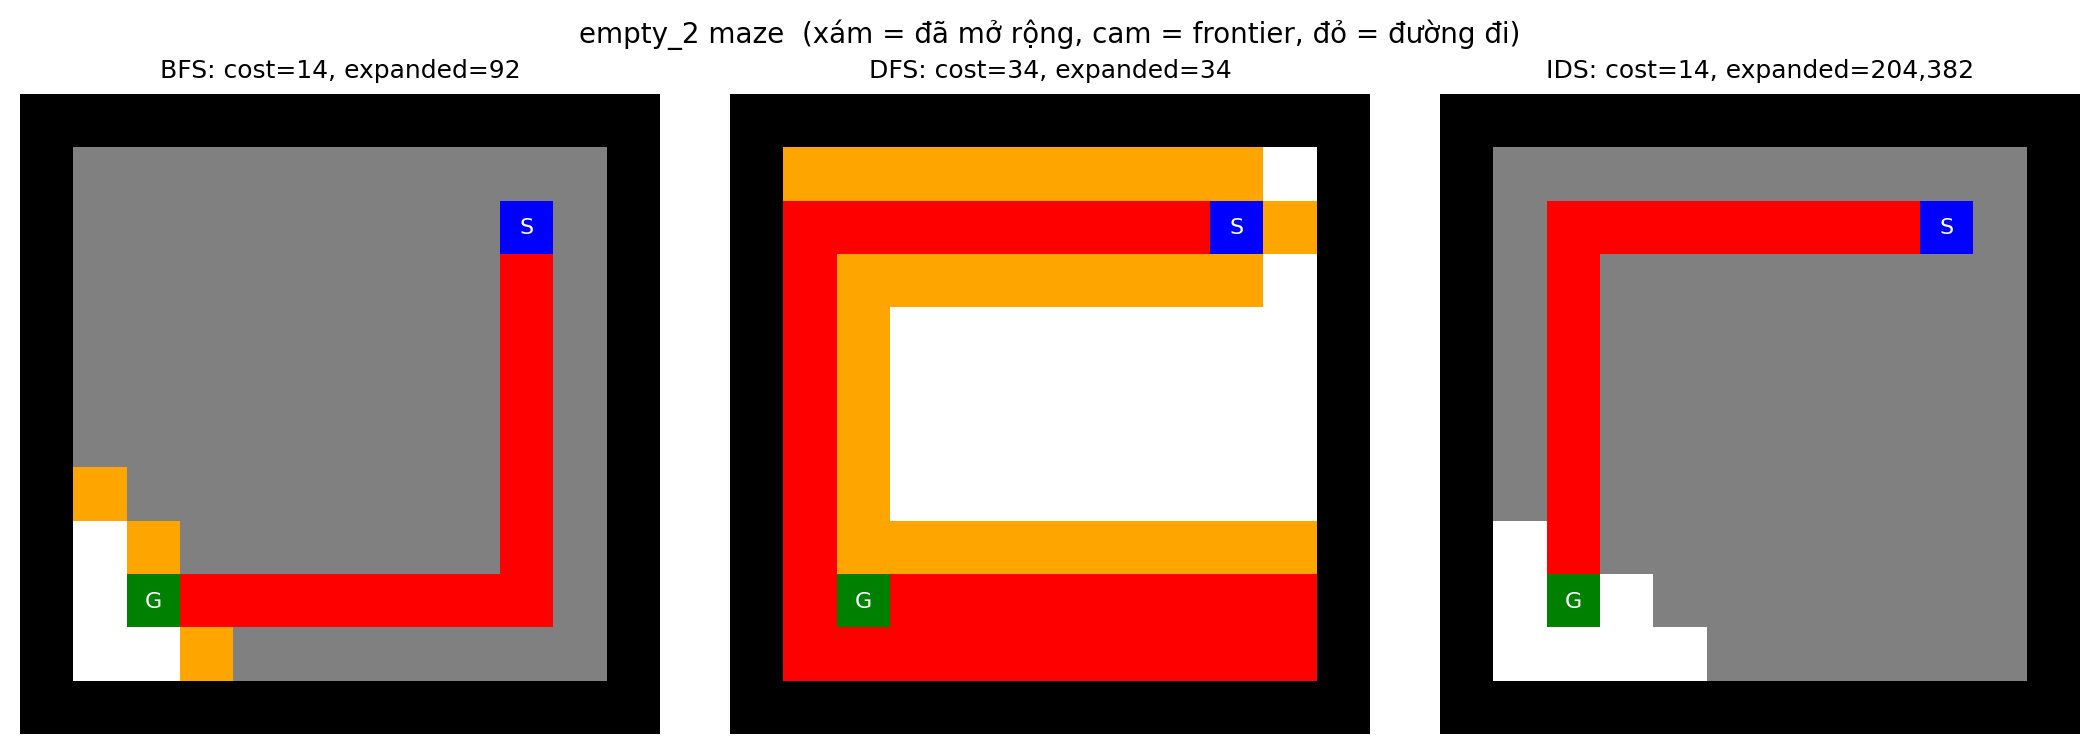

In [134]:
# So sánh trực quan IDS với BFS và DFS. IDS chỉ vẽ ô trong vòng lặp cuối nên frontier/ô mở rộng là của vòng cuối cùng
for m in mazes_dict:
    plot_maze_results(m, ["BFS", "DFS", "IDS"])

**Nhận xét IDS.** IDS gọi lặp lại DFS có giới hạn độ sâu $l=0,1,2,\dots$ (dùng chung `dfs_core` với DFS, vẫn không có `reached`, chỉ có cycle check). Nhờ đó nó **hoàn chỉnh và tối ưu** (chi phí bước bằng 1) như BFS, nhưng bộ nhớ chỉ $O(b\cdot d)$: số nút cùng tồn tại trong bộ nhớ ở empty maze là 33 (BFS: 95), ở large là 248 (BFS: 621), ở medium là 75 (BFS: 269). Riêng kích thước *frontier* thì IDS không nhỏ hơn BFS (large: 38 so với 8), vì không có `reached` nó giữ lại các nút anh em chưa duyệt dọc theo đường đi.

**Cái giá là thời gian.** Mỗi vòng lặp duyệt lại các tầng trên, và với cycle check (không có `reached`) cùng một ô bị duyệt qua nhiều đường khác nhau. Ở mê cung hẹp thì chấp nhận được (small 923 nút, medium 15,665, large 60,179), nhưng ở **vùng trống** số nút bùng nổ: empty maze cần 297,368 lần mở rộng (BFS: 92), còn **L maze và open maze vượt ngưỡng 1,000,000 lần mở rộng** nên ghi `N/A*`. Nguyên nhân: trong không gian rộng, số đường đơn không lặp ô dài $\le l$ tăng theo hàm mũ (xấp xỉ $2.6^l$ trong lưới trống), trong khi số ô khác nhau chỉ tăng bậc hai. Cách khắc phục là thêm `reached` theo độ sâu (mất lợi thế bộ nhớ) hoặc dùng A*/IDA*.

### Multiple Goals
Create a few mazes with multiple goals by adding one or two more goals to the medium size maze. The agent is done when it finds one of the goals.
Solve the maze with your implementations for DFS, BFS, and IDS. Run experiments to show which implementations find the optimal solution and which do not. Discuss why that is the case.

path cost  optimal cost  optimal? goal reached  \
maze          algorithm                                                   
medium_1goal  BFS               68            68      True      (16, 1)   
              DFS              152            68     False      (16, 1)   
              IDS               68            68      True      (16, 1)   
medium_2goals BFS               11            11      True      (3, 25)   
              DFS              152            11     False      (16, 1)   
              IDS               11            11      True      (3, 25)   
medium_3goals BFS               11            11      True      (3, 25)   
              DFS               63            11     False       (8, 8)   
              IDS               11            11      True      (3, 25)   

                         # nodes expanded  max frontier size  
maze          algorithm                                       
medium_1goal  BFS                     267                  9  
              DFS                     153                  8  
              IDS                   15665                  8  
medium_2goals BFS                      21                  3  
              DFS                     153                  8  
              IDS                     112                  3  
medium_3goals BFS                      21                  3  
              DFS                      64                  4  
              IDS                     112                  3

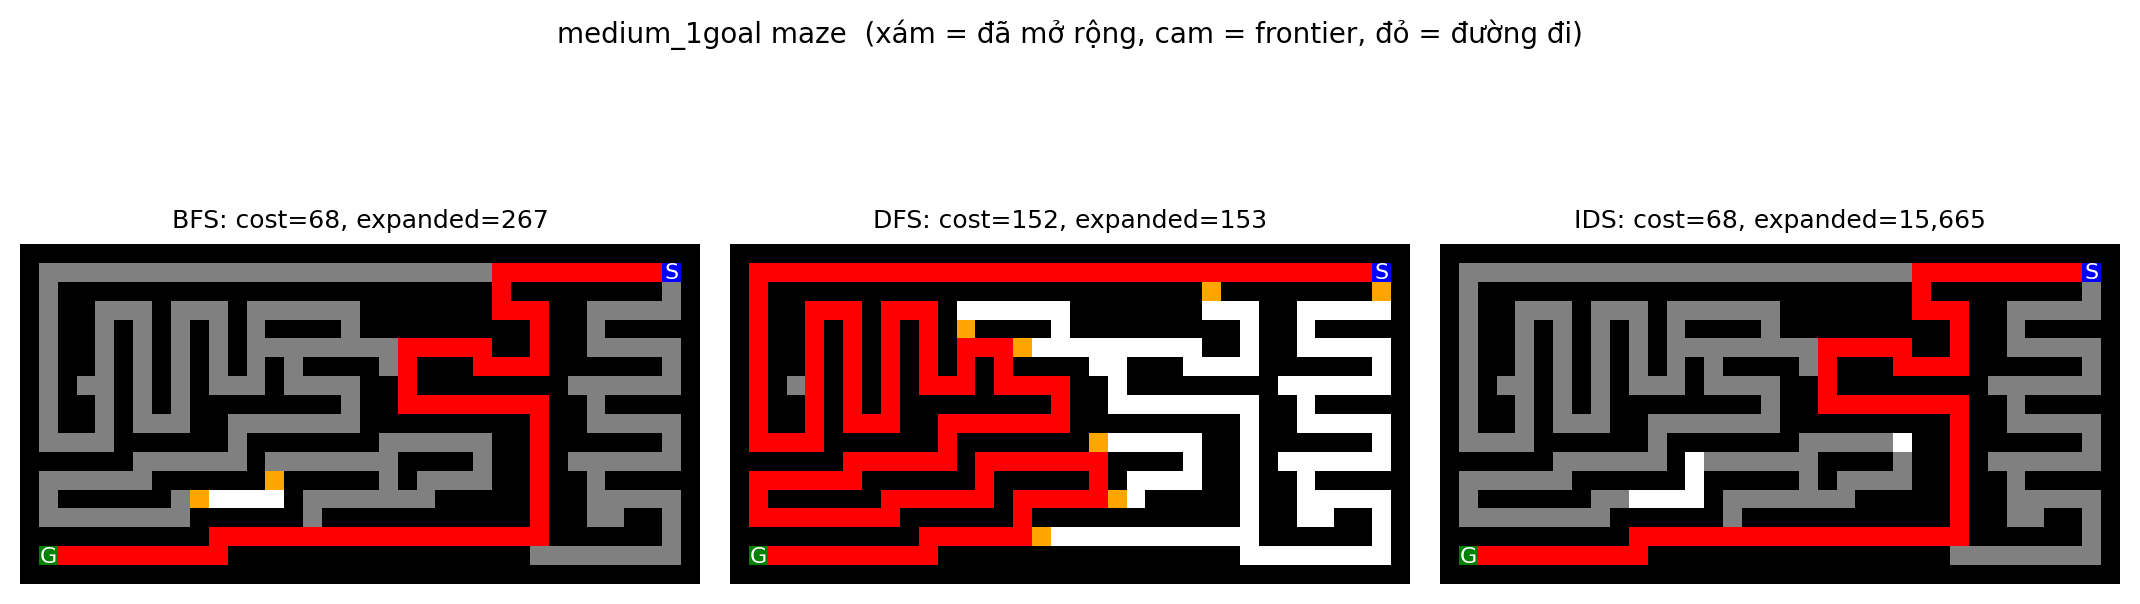

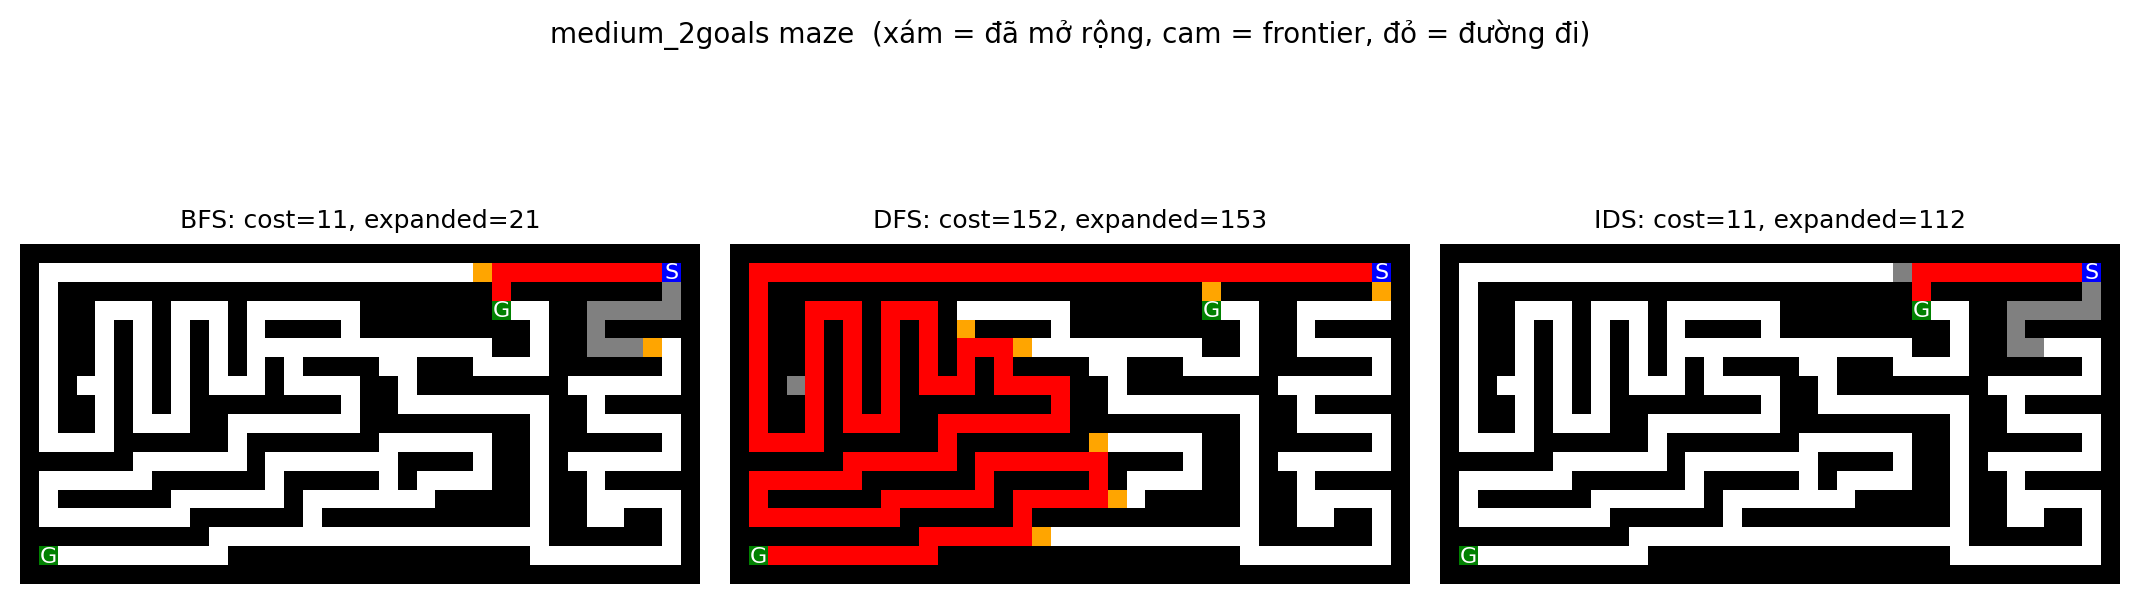

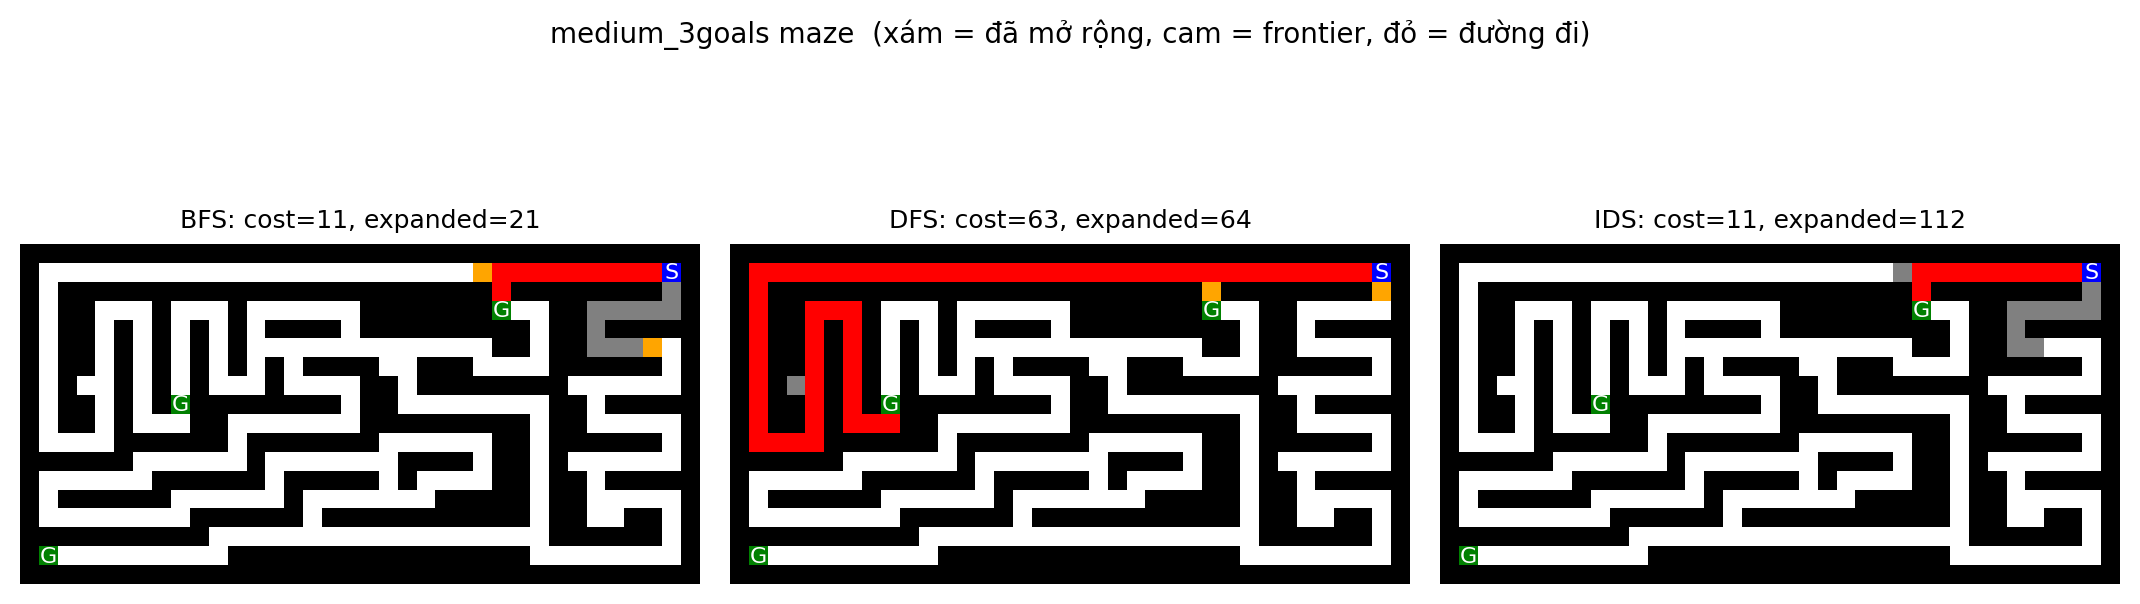

In [135]:
# Mê cung nhiều đích: thêm 1 hoặc 2 đích vào medium maze (các thuật toán dùng tập đích `goals` nên không cần sửa gì)
base = mazes_dict["medium"]

def with_goals(extra):
    m = np.copy(base)
    for p in extra:
        assert m[p] == " ", f"{p} không phải ô trống"
        m[p] = "G"
    return m

multi = {"medium_1goal": base,                                    # đích gốc
         "medium_2goals": with_goals([(3, 25)]),                  # thêm 1 đích
         "medium_3goals": with_goals([(3, 25), (8, 8)])}          # thêm 2 đích

rows_mg = []
for name, mz in multi.items():
    start, goals = get_problem(mz)
    optimal = astar(mz, start, goals)["cost"]          # A* với h = khoảng cách tới đích gần nhất vẫn admissible -> làm chuẩn
    for a in ["BFS", "DFS", "IDS"]:
        r = ALGOS[a](mz, start, goals)
        results[(name, a)] = r
        validate(mz, r)
        rows_mg.append({"maze": name, "algorithm": a, "path cost": r["cost"], "optimal cost": optimal,
                        "optimal?": r["cost"] == optimal, "goal reached": r["path"][-1].pos,
                        "# nodes expanded": r["expanded"], "max frontier size": r["max_frontier"]})
display(pd.DataFrame(rows_mg).set_index(["maze", "algorithm"]))

for name, mz in multi.items():
    plot_maze_results(name, ["BFS", "DFS", "IDS"], maze=mz)

**Nhận xét về mê cung nhiều đích.** Cột `optimal cost` được tính bằng A\* (heuristic là khoảng cách tới đích *gần nhất* nên vẫn admissible), dùng làm chuẩn để so sánh.

* **BFS** luôn tối ưu. Nó mở rộng theo từng tầng nên đích đầu tiên nó sinh ra là đích gần nhất, dù có bao nhiêu đích.
* **IDS** tối ưu vì cùng lý do: giới hạn độ sâu tăng dần từng bước nên gặp đích nông nhất trước (đổi lại mở rộng nhiều nút hơn BFS: 112 so với 21 ở bản có thêm đích).
* **DFS** **không** đảm bảo tối ưu. Nó đi sâu theo nhánh chọn đầu tiên và dừng ở đích đầu tiên gặp, có thể là đích xa. Trong thí nghiệm, đích thêm vào ở (3, 25) chỉ cách 11 bước nhưng DFS vẫn đi 152 bước tới đích gốc, và ở bản 3 đích nó dừng ở đích (8, 8) với 63 bước. Thêm đích có thể làm DFS dừng sớm hơn nhưng không làm đường đi tốt hơn, vì thứ tự duyệt của DFS không liên quan tới khoảng cách.


BFS / DFS / IDS theo từng mê cung

=== small maze ===


,maze,algorithm,path cost,# nodes expanded,max tree depth,max # nodes in memory,max frontier size,time (ms)
0,small,BFS,19,90,19,92,9,0.55
1,small,DFS,29,39,29,34,5,0.28
2,small,IDS,19,923,19,25,6,6.2



=== medium maze ===


,maze,algorithm,path cost,# nodes expanded,max tree depth,max # nodes in memory,max frontier size,time (ms)
0,medium,BFS,68,267,68,269,9,1.98
1,medium,DFS,152,153,152,160,8,1.99
2,medium,IDS,68,15665,68,75,8,142.69



=== large maze ===


...

,maze,algorithm,path cost,# nodes expanded,max tree depth,max # nodes in memory,max frontier size,time (ms)
0,loops,BFS,23,70,23,71,8,0.4
1,loops,DFS,27,30,27,39,12,0.26
2,loops,IDS,23,60701,23,36,14,529.66



=== empty maze ===


,maze,algorithm,path cost,# nodes expanded,max tree depth,max # nodes in memory,max frontier size,time (ms)
0,empty,BFS,14,92,14,95,12,0.54
1,empty,DFS,80,80,80,153,73,1.2
2,empty,IDS,14,297368,14,33,19,3196.93



=== empty_2 maze ===


,maze,algorithm,path cost,# nodes expanded,max tree depth,max # nodes in memory,max frontier size,time (ms)
0,empty_2,BFS,14,92,14,95,11,0.53
1,empty_2,DFS,34,34,34,76,42,0.35
2,empty_2,IDS,14,204382,14,39,25,2240.37


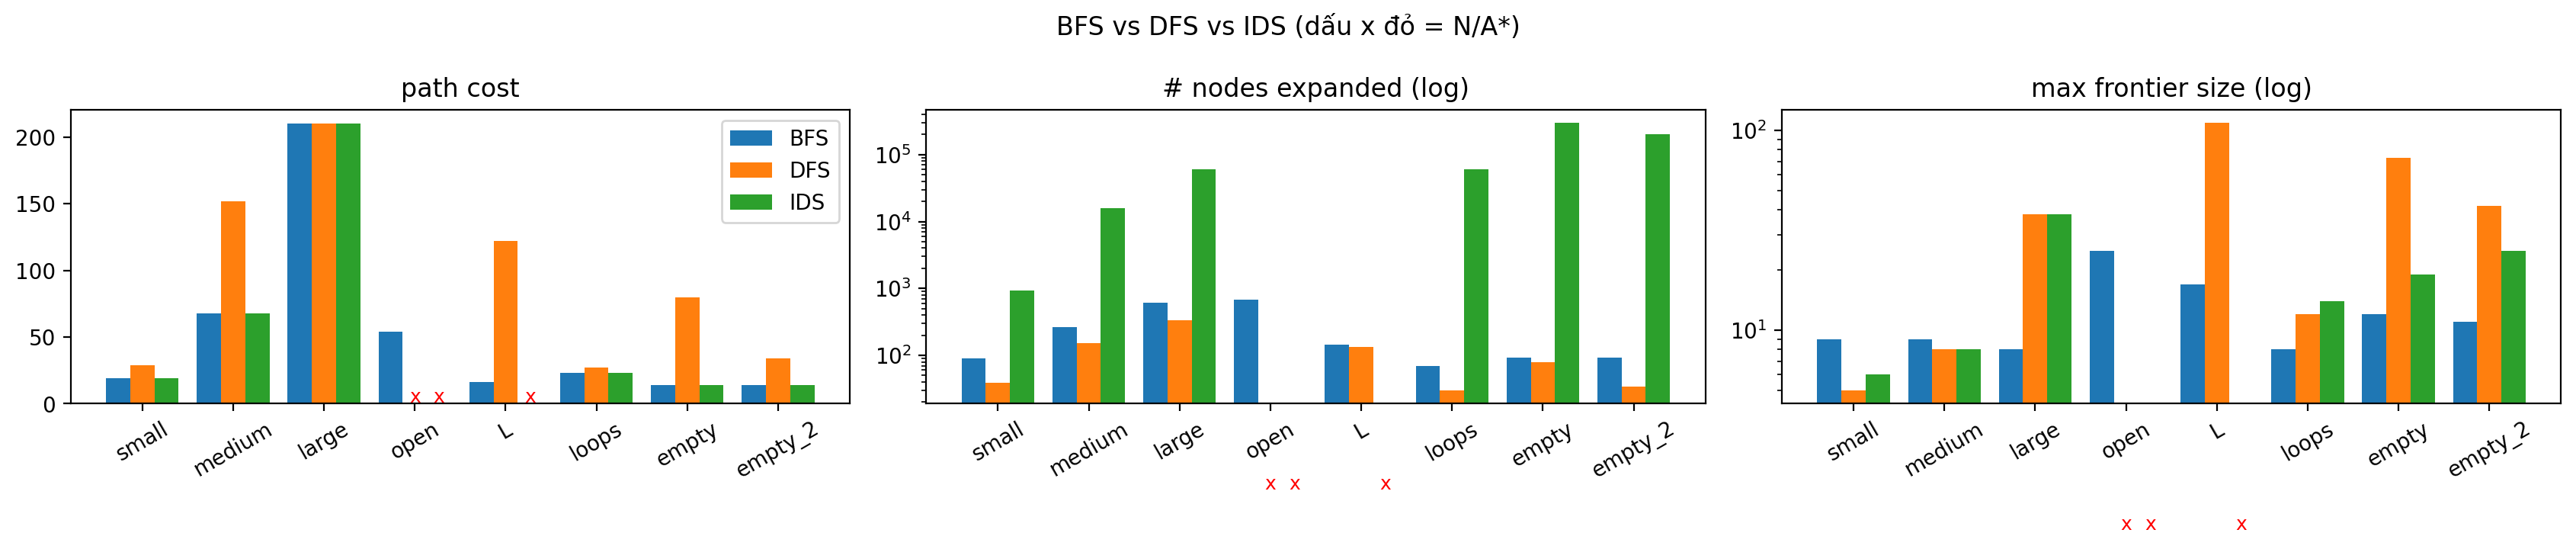

In [136]:
# Bảng riêng theo từng mê cung cho BFS, DFS, IDS
print("\nBFS / DFS / IDS theo từng mê cung")
df_all = summary_table(list(mazes_dict), ["BFS", "DFS", "IDS"])
for m in mazes_dict:
    print(f"\n=== {m} maze ===")
    show_table(df_all[df_all["maze"] == m])

plot_metrics(df_all, ["BFS", "DFS", "IDS"], "BFS vs DFS vs IDS (dấu x đỏ = N/A*)")

## More Advanced Problems to Think About (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment.

### Intersection as States
Instead of defining each square as a state, use only intersections as states. Now the storage requirement is reduced, but the path length between two intersections can be different. If we use total path length measured as the number of squares as path cost, how can we make sure that BFS and iterative deepening search is optimal? Change the code to do so.

In [137]:
# ---- Intersections as states ----
def free_neighbors(m, pos):
    """các ô không phải tường cạnh pos, dạng danh sách (action, ô)"""
    return [(a, (pos[0] + dr, pos[1] + dc)) for a, (dr, dc) in ACTIONS.items()
            if m[pos[0] + dr, pos[1] + dc] != "X"]

def on_path(node, pos):
    """cycle check: pos đã nằm trên đường từ gốc tới node chưa?"""
    while node is not None:
        if node.pos == pos:
            return True
        node = node.parent
    return False

def build_graph(m):
    """Nén mê cung: trạng thái là ô start, ô đích, ngõ cụt và giao lộ (ô có 3-4 ô trống kề bên).
    Mỗi hành lang nối hai trạng thái thành một cạnh có chi phí = số ô (số bước) của hành lang.
    Trả về start, goals và graph = {trạng thái: [(trạng thái kế, số bước, các hành động), ...]}"""
    start, goals = get_problem(m)
    goals = list(goals)
    free = [(int(r), int(c)) for r, c in zip(*np.where(m != "X"))]
    states = set(goals) | {start}
    for p in free:
        if len(free_neighbors(m, p)) != 2:        # giao lộ hoặc ngõ cụt
            states.add(p)
    graph = {}
    for s in states:
        graph[s] = []
        for a, cur in free_neighbors(m, s):
            prev, steps, acts = s, 1, [a]
            while cur not in states:              # đi dọc hành lang tới trạng thái kế tiếp
                (a2, nxt), = [(a2, n2) for a2, n2 in free_neighbors(m, cur) if n2 != prev]
                prev, cur = cur, nxt
                steps += 1
                acts.append(a2)
            graph[s].append((cur, steps, acts))
    return start, goals, graph

def graph_result(node, stats):
    """kết quả cho đồ thị đã nén (cost = số ô đã đi)"""
    if node is None:
        return {"path": None, "actions": None, "cost": None, **stats}
    path = node.get_path_from_root()
    return {"path": [n.pos for n in path], "actions": [a for n in path[1:] for a in n.action],
            "cost": node.cost, **stats}

def bfs_graph(m):
    """BFS thường trên đồ thị đã nén: mở rộng theo số CẠNH, không phải số ô"""
    start, goals, graph = build_graph(m)
    root = Node(start, None, None, 0)
    stats = {"expanded": 0, "max_frontier": 1}
    if start in goals:
        return graph_result(root, stats)
    frontier, reached = deque([root]), {start}
    while frontier:
        node = frontier.popleft()
        stats["expanded"] += 1
        for nxt, steps, acts in graph[node.pos]:
            if nxt not in reached:
                child = Node(nxt, node, acts, node.cost + steps)
                if nxt in goals:                  # early goal test: dừng ở đường có ít cạnh nhất
                    return graph_result(child, stats)
                reached.add(nxt)
                frontier.append(child)
        stats["max_frontier"] = max(stats["max_frontier"], len(frontier))
    return graph_result(None, stats)

def ucs_graph(m):
    """BFS sửa lại để tối ưu khi chi phí bước khác nhau = uniform-cost search:
    frontier sắp theo chi phí đường đi g(n) và kiểm tra đích khi lấy nút ra."""
    start, goals, graph = build_graph(m)
    stats = {"expanded": 0, "max_frontier": 1}
    counter = 0
    frontier = [(0, counter, Node(start, None, None, 0))]
    best = {start: 0}
    while frontier:
        g, _, node = heapq.heappop(frontier)
        if g > best[node.pos]:
            continue                              # bản cũ, đắt hơn của cùng một trạng thái
        if node.pos in goals:
            return graph_result(node, stats)
        stats["expanded"] += 1
        for nxt, steps, acts in graph[node.pos]:
            if nxt not in best or g + steps < best[nxt]:
                best[nxt] = g + steps
                counter += 1
                heapq.heappush(frontier, (g + steps, counter, Node(nxt, node, acts, g + steps)))
        stats["max_frontier"] = max(stats["max_frontier"], len(frontier))
    return graph_result(None, stats)

def ids_graph(m, max_expanded=200_000):
    """IDS sửa lại để tối ưu khi chi phí bước khác nhau = iterative lengthening search:
    DFS giới hạn theo CHI PHÍ ĐƯỜNG ĐI (không phải độ sâu). Nếu chưa thấy đích, giới hạn mới là
    chi phí nhỏ nhất đã bị cắt ở vòng trước, nên không bỏ sót chi phí nào."""
    start, goals, graph = build_graph(m)
    stats = {"expanded": 0, "max_frontier": 1, "iterations": 0}
    limit = 0
    while True:
        stats["iterations"] += 1
        next_limit = float("inf")
        frontier = [Node(start, None, None, 0)]
        while frontier:
            node = frontier.pop()
            if node.pos in goals:
                return graph_result(node, stats)
            if stats["expanded"] >= max_expanded:
                return graph_result(None, {**stats, "gave_up": True})
            stats["expanded"] += 1
            for nxt, steps, acts in graph[node.pos]:
                if node.cost + steps > limit:
                    next_limit = min(next_limit, node.cost + steps)   # bị cắt, nhớ lại chi phí này
                elif not on_path(node, nxt):                          # cycle checking
                    frontier.append(Node(nxt, node, acts, node.cost + steps))
            stats["max_frontier"] = max(stats["max_frontier"], len(frontier))
        if next_limit == float("inf"):
            return graph_result(None, stats)      # đã duyệt hết mà không có đích
        limit = next_limit


# So sánh trên mọi mê cung: chi phí tối ưu (A* trên các ô) và 3 thuật toán trên đồ thị đã nén
rows = []
for name, m in mazes_dict.items():
    start, goals, graph = build_graph(m)
    optimal = astar(m, *get_problem(m))["cost"]
    row = {"maze": name, "số ô": int((m != "X").sum()), "số trạng thái (giao lộ)": len(graph),
           "chi phí tối ưu": optimal}
    for label, alg in {"BFS (ít cạnh nhất)": bfs_graph, "uniform-cost": ucs_graph,
                       "IDS (giới hạn chi phí)": ids_graph}.items():
        res = alg(m)
        row[label + ": cost"] = "N/A*" if res["path"] is None else res["cost"]
        row[label + ": expanded"] = res["expanded"]
    rows.append(row)
pd.DataFrame(rows).set_index("maze")

,số ô,số trạng thái (giao lộ),chi phí tối ưu,BFS (ít cạnh nhất): cost,BFS (ít cạnh nhất): expanded,uniform-cost: cost,uniform-cost: expanded,IDS (giới hạn chi phí): cost,IDS (giới hạn chi phí): expanded
maze,,,,,,,,,
small,94,14,19,29,10,19,12,19,156
medium,274,21,68,68,18,68,20,68,1179
large,647,179,210,210,171,210,171,210,8593
open,684,674,54,54,671,54,673,N/A*,200000
L,157,152,16,16,142,16,147,N/A*,200000
loops,72,39,23,23,37,23,38,23,58500
empty,100,96,14,14,89,14,92,N/A*,200000
empty_2,100,96,14,14,89,14,92,N/A*,200000


**Trả lời.** Nếu chỉ lấy giao lộ làm trạng thái thì các hành lang giữa chúng trở thành cạnh có độ dài khác nhau, nên chi phí đường đi (số ô) không còn bằng độ sâu trong cây nữa.

* **BFS** mở rộng theo tầng, tức là tìm đường có ít *cạnh* (ít giao lộ) nhất chứ không phải ít *ô* nhất, nên không còn tối ưu. Ví dụ ở small maze, BFS trên đồ thị giao lộ ra đường 29 trong khi tối ưu là 19.
* **Cách sửa cho BFS:** sắp frontier theo chi phí đường đi $g(n)$ (hàng đợi ưu tiên) và kiểm tra đích khi lấy nút ra khỏi frontier. Đó chính là uniform-cost search, tối ưu với mọi chi phí bước dương, và cho ra 19 ở small maze.
* **Cách sửa cho IDS:** dùng chi phí đường đi làm giới hạn thay cho độ sâu (iterative lengthening search). Mỗi vòng là một DFS không vượt quá giới hạn chi phí, và giới hạn của vòng sau là chi phí nhỏ nhất đã bị cắt ở vòng trước, nên không bỏ sót chi phí nào và đích đầu tiên tìm được là tối ưu.
* **Lưu trữ:** số trạng thái giảm mạnh ở mê cung hành lang (small: 14 thay vì 94 ô, medium: 21 thay vì 274, large: 179 thay vì 647), và uniform-cost mở rộng ít nút hơn nhiều so với BFS trên từng ô (small: 12 so với 90, medium: 20 so với 267). Ở vùng trống (open, empty) hầu như ô nào cũng là giao lộ nên gần như không tiết kiệm được gì.
* **Vấn đề còn lại:** IDS theo chi phí vẫn không có `reached` nên gặp lại vấn đề cũ ở vùng trống: ở open, L, empty và empty_2 nó chạm ngưỡng 200,000 lần mở rộng (`N/A*`).

### Weighted A* search
Modify your A* search to add weights (see text book) and explore how different weights influence the result.

In [138]:
# Weighted A*: f(n) = g(n) + w * h(n)
rows = []
for name in ["medium", "large", "open", "empty"]:
    m = mazes_dict[name]; s, gs = get_problem(m)
    for w in [1, 1.5, 2, 3, 5]:
        r = astar(m, s, gs, weight=w)
        rows.append({"maze": name, "weight": w, "path cost": r["cost"], "expanded": r["expanded"]})
pd.DataFrame(rows).pivot(index="weight", columns="maze", values=["path cost", "expanded"])

path cost                   expanded                  
maze       empty large medium open    empty large medium open
weight                                                       
1.0           14   210     68   54       63   549    221  535
1.5           14   210     68   58       14   522    229  203
2.0           14   210     68   62       14   510    228  203
3.0           14   210     68   66       14   510    226  153
5.0           14   210     74   68       14   495     78   98

Với $w = 1$ ta có A\* thường (tối ưu). Trọng số càng lớn thì thuật toán càng tin vào heuristic và càng giống GBFS: thường mở rộng ít nút hơn (open maze: 535 nút với $w=1$ nhưng chỉ 98 nút với $w=5$) nhưng đường đi có thể dài hơn tối ưu (open maze: cost 54 với $w=1$ và 68 với $w=5$), vì khi $w > 1$ heuristic không còn admissible. Ở mê cung hành lang như large thì trọng số gần như không đổi gì về chi phí. Vậy trọng số là sự đánh đổi giữa tốc độ và chất lượng lời giải.

### Unknown Maze
What happens if the agent does not know the layout of the maze in advance? This means that the agent faces an unknown environment, where it does not know the transition function. How does the environment look then (PEAS description)? How would you implement a rational agent to solve the maze? What if the agent still has a GPS device to tell the distance to the goal?

**Mô tả PEAS (mê cung chưa biết):**

* **Performance (hiệu suất):** tới đích với ít bước nhất (và khám phá ít nhất) có thể.
* **Environment (môi trường):** mê cung dạng lưới có tường, không biết trước bố cục, agent chỉ biết vị trí của mình. Môi trường quan sát một phần và tuần tự, nhưng vẫn rời rạc, tĩnh và xác định.
* **Actuators (cơ cấu tác động):** di chuyển N/E/S/W.
* **Sensors (cảm biến):** vị trí hiện tại $(x, y)$ và 4 ô xung quanh có phải tường không (và có đang đứng trên đích không).

Vì agent không biết trước hàm chuyển trạng thái nên không thể lập sẵn cả kế hoạch (không có open-loop plan). Nó phải **vừa đi vừa khám phá** và tự vẽ bản đồ của mình, ví dụ dùng kiểu DFS nhớ các ô đã đi và quay lui ở ngõ cụt. Cách này tìm được đích trong mê cung hữu hạn (đầy đủ) nhưng không đảm bảo đường ngắn nhất. Khi đã biết bản đồ thì agent có thể lập kế hoạch bằng A\* trên bản đồ vừa dựng. Nếu agent có thêm GPS báo khoảng cách tới đích thì dùng nó như heuristic: luôn thử ô kề có khoảng cách nhỏ nhất trước (kiểu online greedy search / LRTA\*), thường tới đích nhanh hơn nhiều, dù vẫn có thể bị tường đánh lừa.